> 1. READ MUTATION DATA 

> 2. RANDOMFOREST MODEL

> 3. XGB MODEL

> 4. LGBM MODEL

> 1. READ MUTATION DATA (GOF, LOF)

In [ ]:
# import pandas as pd
# import numpy as np
# import xgboost as xgb
# from sklearn.metrics import f1_score, classification_report, confusion_matrix
# import warnings
# import re

# # Suppress warnings for clean cell outputs
# warnings.filterwarnings('ignore')
# print("Libraries loaded successfully.")

# print("Loading Balanced Train Data and Imbalanced External Validation Data...")

# # Load the Parquet files
# train_df = pd.read_parquet("train_data.parquet")
# test_val_df = pd.read_parquet("external_val_data.parquet") # <-- THE VAULT
# test_df = pd.read_parquet("test_data.parquet")

# # Drop the label and noisy columns
# columns_to_drop = [ 'Unnamed: 0', 'Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD']
# train_df = train_df.drop(columns=columns_to_drop, errors='ignore')
# test_val_df = test_val_df.drop(columns=columns_to_drop, errors='ignore')
# test_df = test_df.drop(columns=columns_to_drop, errors='ignore')

# # make new_hgnc_agg_ids the index for all three dataframes
# train_df.set_index('new_hgnc_agg_ids', inplace=True)
# test_val_df.set_index('new_hgnc_agg_ids', inplace=True)
# test_df.set_index('new_hgnc_agg_ids', inplace=True)

# # Drop rows that are 2 in goflof in datasets (only GOF vs LOF)
# train_df = train_df[train_df['goflof'] != 2]
# test_val_df = test_val_df[test_val_df['goflof'] != 2]
# test_df = test_df[test_df['goflof'] != 2]


Libraries loaded successfully.
Loading Balanced Train Data and Imbalanced External Validation Data...


In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import warnings
import re
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.model_selection import StratifiedGroupKFold

# 1. Load the perfectly balanced training datasets
# GOF total = 1400. LOF total = 1400.
gof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_train_1400.csv", index_col=0) # eve_score nan 31%
## gof_train['eve_score'].fillna(gof_train['eve_score'].mean(), inplace=True)
lof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_train_1400.csv", index_col=0) # eve_score nan 0%
# 2. Combine and Split 80/20 
gof_lof_train = pd.concat([gof_train, lof_train], ignore_index=True)
gof_lof_train['gene'] = gof_lof_train['new_hgnc_agg_ids'].str.split('_').str[0]  # Extract gene name from new_hgnc_agg_ids

from sklearn.model_selection import StratifiedGroupKFold

# # Loop through seeds to find a well-balanced split
# for seed in range(100):
#     sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
#     train_idx, test_idx = next(sgkf.split(gof_lof_train, gof_lof_train['goflof'], groups=gof_lof_train['gene']))
    
#     test_ratio = gof_lof_train.iloc[test_idx]['goflof'].mean()
    
#     # Target approximately 50% (0.50) GOF ratio in the test set
#     if 0.495 <= test_ratio <= 0.505:
#         print(f"Found great seed: {seed} (Test GOF Ratio: {test_ratio:.2%})")
#         break
#########################################################################################################################
# Set up a 5-fold split (1 fold = 20% test, 4 folds = 80% train)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=14)

# Get indices for the first fold
train_idx, test_idx = next(
    sgkf.split(
        X=gof_lof_train, 
        y=gof_lof_train['goflof'], 
        groups=gof_lof_train['gene']
    )
)

# Create train and test DataFrames
train_df = gof_lof_train.iloc[train_idx].reset_index(drop=True)
test_df = gof_lof_train.iloc[test_idx].reset_index(drop=True)
# ---------------------------------------------------------
# Print Summary Statistics
# ---------------------------------------------------------

print("=== GENE COUNTS ===")
print(f"Train Unique Genes : {train_df['gene'].nunique()}")
print(f"Test Unique Genes  : {test_df['gene'].nunique()}")

# Verify zero gene overlap
gene_overlap = set(train_df['gene']).intersection(set(test_df['gene']))
print(f"Gene Overlap Count : {len(gene_overlap)}")

print("\n=== CLASS DISTRIBUTION (Variants) ===")
print("Train Class Counts:")
print(train_df['goflof'].value_counts())

print("\nTest Class Counts:")
print(test_df['goflof'].value_counts())

print("\n=== CLASS PERCENTAGES ===")
print("Train Class Ratio (%):")
print((train_df['goflof'].value_counts(normalize=True) * 100).round(2))

print("\nTest Class Ratio (%):")
print((test_df['goflof'].value_counts(normalize=True) * 100).round(2))
#########################################################################################################################
# 3 . Load validation datasets
gof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_val_325.csv", index_col=0) # eve_score nan 21%
## gof_val['eve_score'].fillna(gof_val['eve_score'].mean(), inplace=True)
lof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_val_325.csv", index_col=0) # eve_score nan 8%
##lof_val['eve_score'].fillna(lof_val['eve_score'].mean(), inplace=True)
# 4 . Combine validation datasets
test_val_df = pd.concat([gof_val, lof_val], ignore_index=True)

# 5. drop col [ 'Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD']
cols_drop = ['Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD', 'protein_len']
train_df.drop(columns=cols_drop, inplace=True)
test_df.drop(columns=cols_drop, inplace=True)
test_val_df.drop(columns=cols_drop, inplace=True)
# set new_hgnc_agg_ids as index for all three dataframes
train_df.set_index('new_hgnc_agg_ids', inplace=True)
test_df.set_index('new_hgnc_agg_ids', inplace=True)
test_val_df.set_index('new_hgnc_agg_ids', inplace=True)
# drop gene from  train and test datasets
train_df.drop(columns=['gene'], inplace=True)   
test_df.drop(columns=['gene'], inplace=True)


=== GENE COUNTS ===
Train Unique Genes : 187
Test Unique Genes  : 56
Gene Overlap Count : 0

=== CLASS DISTRIBUTION (Variants) ===
Train Class Counts:
goflof
0    917
1    917
Name: count, dtype: int64

Test Class Counts:
goflof
0    483
1    483
Name: count, dtype: int64

=== CLASS PERCENTAGES ===
Train Class Ratio (%):
goflof
0    50.0
1    50.0
Name: proportion, dtype: float64

Test Class Ratio (%):
goflof
0    50.0
1    50.0
Name: proportion, dtype: float64


In [2]:
test_val_genes  = test_val_df[['goflof']]
test_val_genes['gene']  = test_val_genes.index.str.split('_').str[0]  # Extract gene names from new_hgnc_agg_ids
# count genes that are in GOF = 0, and LOF = 1
gof_genes = set(test_val_df[test_val_df['goflof'] == 0].index.str.split('_').str[0])
lof_genes = set(test_val_df[test_val_df['goflof'] == 1].index.str.split('_').str[0])
print(f"GOF Genes in Validation Set: {len(gof_genes)}")
print(f"LOF Genes in Validation Set: {len(lof_genes)}")
# shared genes between GOF and LOF in the validation set
shared_genes = set(test_val_df[test_val_df['goflof'] == 0].index.str.split('_').str[0]).intersection(set(test_val_df[test_val_df['goflof'] == 1].index.str.split('_').str[0]))
print(f"Shared Genes in Validation Set: {len(shared_genes)}")

GOF Genes in Validation Set: 22
LOF Genes in Validation Set: 20
Shared Genes in Validation Set: 7


/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_20171/1077390645.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_val_genes['gene']  = test_val_genes.index.str.split('_').str[0]  # Extract gene names from new_hgnc_agg_ids


> 1.1 Data Cleaning

In [3]:

# balance the dataset by keeping 895 samples from each class in the train_df

# Drop the label and noisy columns
X_train = train_df.drop(columns='goflof', errors='ignore')
y_train_orig = train_df['goflof']

X_test = test_df.drop(columns='goflof', errors='ignore')
y_test_orig = test_df['goflof']

# Clean XGBoost's forbidden characters from column names
def clean_cols(df):
    new_cols = []
    for col in df.columns:
        c = col.strip()
        c = re.sub(r'[\[\]<>]', '_', c)
        new_cols.append(c)
    df.columns = new_cols
    return df

X_train = clean_cols(X_train) # 58 features
X_test = clean_cols(X_test)

print(f"Training shape: {X_train.shape}")
print(f"Holdout shape: {X_test.shape}")

Training shape: (1834, 60)
Holdout shape: (966, 60)


1.2 Feature Engeneering

In [4]:
def feature_engineering(df):
    df = df.copy()
    
    # 1. Surface accessibility and rigidity interactions
    df['buried'] = (df['rsa'] < 0.15).astype(float)
    df['exposed'] = (df['rsa'] > 0.45).astype(float)
    df['rigid'] = (df['plddt_score'] > 85).astype(float)
    df['flexible'] = (df['plddt_score'] < 60).astype(float)
    df['disordered'] = (df['disorder'] > 0.5).astype(float)
    
    df['exposed_flexible'] = df['exposed'] * df['flexible']
    df['buried_rigid'] = df['buried'] * df['rigid']
    # df['small_protein'] = (df['protein_len'] < 300).astype(float)
    # df['small_protein_buried'] = df['small_protein'] * df['buried']
    
    # 2. Charge and Hydrophobicity changes
    df['charge_change'] = df['BuriedCharge-MUTANT-CHARGE'] - df['BuriedCharge-NATIVE-CHARGE']
    df['abs_charge_change'] = df['charge_change'].abs()
    df['hphob_change_core'] = df['CorePhilic-MUTANT-HPHOB'] - df['CorePhilic-NATIVE-HPHOB']
    df['abs_hphob_change_core'] = df['hphob_change_core'].abs()
    df['hphob_change_surf'] = df['SurfacePhobic-MUTANT-HPHOB'] - df['SurfacePhobic-NATIVE-HPHOB']
    df['abs_hphob_change_surf'] = df['hphob_change_surf'].abs()
    # df['charge_disruption_density'] = df['abs_charge_change'] / np.log1p(df['protein_len'])
    
    # 3. Energy differences
    df['glycine_energy_change'] = df['Glycine-MUTANT-ENERGY'] - df['Glycine-NATIVE-ENERGY']
    df['proline_energy_change'] = df['Proline-MUTANT-ENERGY'] - df['Proline-NATIVE-ENERGY']
    
    # 4. Ratios and products
    df['rsa_x_asa'] = df['rsa'] * df['asa']
    df['rsa_x_plddt'] = df['rsa'] * df['plddt_score']
    df['disorder_x_plddt'] = df['disorder'] * df['plddt_score']
    
    # 5. Non-linear AlphaMissense features
    df['am_pathogenicity_sq'] = df['am_pathogenicity'] ** 2
    
    # 6. Interaction with energies
    df['clash_x_buried'] = df['Clash-ENERGY'] * df['buried']
    df['hbonds_x_buried'] = df['HBonds-ENERGY'] * df['buried']
    
    # 7. Conformation disruptions
    df['glycine_disruption'] = df['Glycine-BOOL'] * df['Glycine-MUTANT-ENERGY']
    df['proline_disruption'] = df['Proline-BOOL'] * df['Proline-MUTANT-ENERGY']
    
    return df

print("Applying feature engineering...")
X_train = feature_engineering(X_train) # 83 features after engineering
X_test = feature_engineering(X_test)
# X_train = X_train.drop(columns=['protein_len'], errors='ignore')
# X_test = X_test.drop(columns=['protein_len'], errors='ignore')
print("Done. Ready for feature selection.")
print(f" All features: {X_train.columns.tolist()}")

Applying feature engineering...
Done. Ready for feature selection.
 All features: ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'BuriedCharge-BOOL', 'BuriedCharge-MUTANT-CHARGE', 'CisPro-OMEGA', 'CisPro-BOOL', 'Clash-ENERGY', 'Clash-BOOL', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-BOOL', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-NATIVE-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'Glycine-NATIVE-BOOL', 'Glycine-BOOL', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-BOOL', 'HBonds-ENERGY', 'Proline-NATIVE-ENERGY', 'Proline-PHI', 'Proline-NATIVE-BOOL', 'Proline-BOOL', 'Proline-MUTANT-ENERGY', 'Proline-PSI', 'SSGeom-BOOL', 'SurfacePhobic-MUTANT-HPHOB', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'SurfacePhobic-BOOL', 'Voids-BOOL', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'methylation', 'ubiquitination', 'acetylation', 'sumoylatio

1. Random Forest after fixing Data leakage

Running RFECV for feature selection on Training Set...
RF optimal features: 37 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-PHI', 'Glycine-PSI', 'Proline-PHI', 'Proline-PSI', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'pro_domain_num', 'conservation_score', 'esm_score', 'eve_score', 'rigid', 'hphob_change_core', 'abs_hphob_change_core', 'hphob_change_surf', 'abs_hphob_change_surf', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt', 'am_pathogenicity_sq']


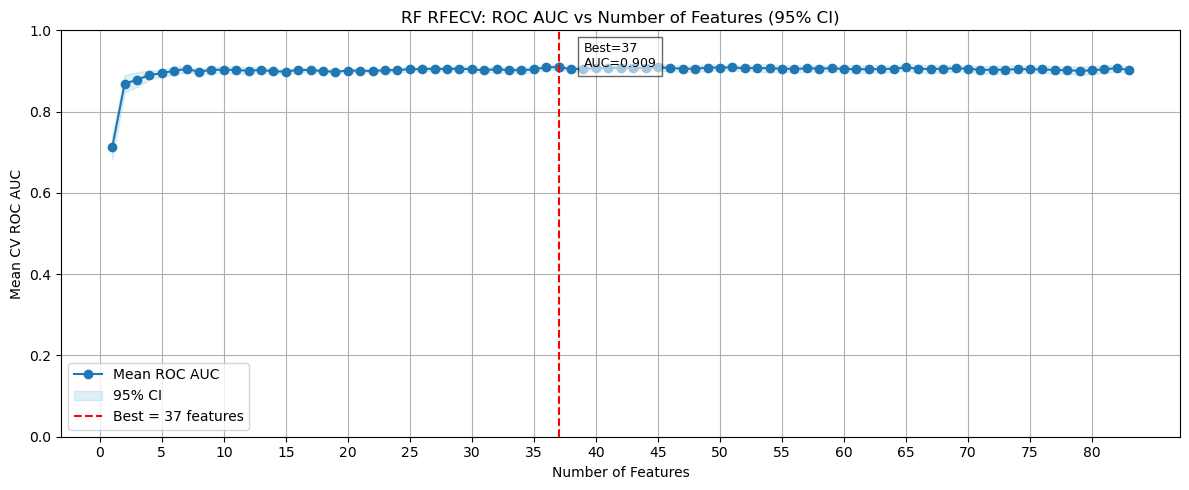

Best Parameters : {'max_depth': None, 'n_estimators': 300}
Best CV ROC AUC : 0.907

★ Optimal Threshold determined from Train OOF (Youden-J): 0.4565
  Train OOF Sensitivity (LOF recall) : 0.840
  Train OOF Specificity (GOF recall) : 0.792


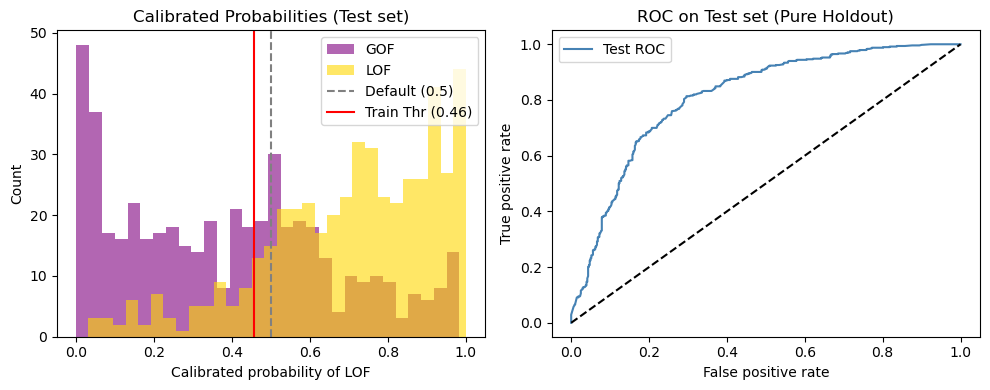


--- Test Set: Default threshold (0.5) ---


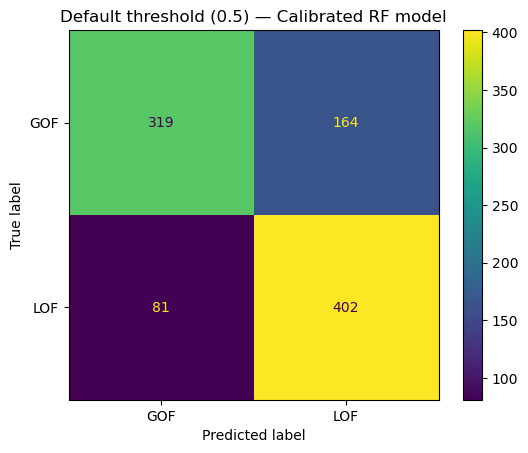

              precision    recall  f1-score   support

         GOF       0.80      0.66      0.72       483
         LOF       0.71      0.83      0.77       483

    accuracy                           0.75       966
   macro avg       0.75      0.75      0.74       966
weighted avg       0.75      0.75      0.74       966


--- Test Set: Applied Train-Derived Threshold (0.456) ---


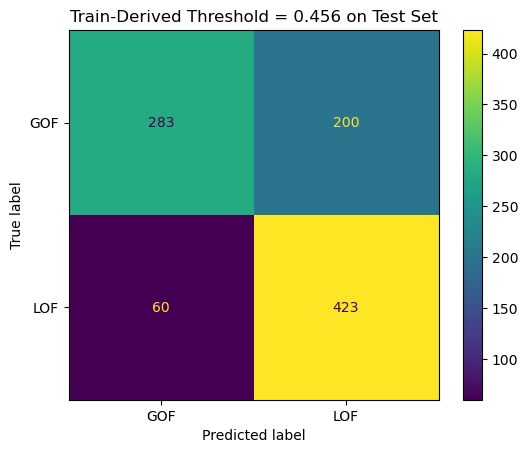

              precision    recall  f1-score   support

         GOF       0.83      0.59      0.69       483
         LOF       0.68      0.88      0.76       483

    accuracy                           0.73       966
   macro avg       0.75      0.73      0.73       966
weighted avg       0.75      0.73      0.73       966


★ RF External Validation AUC (calibrated): 0.7832


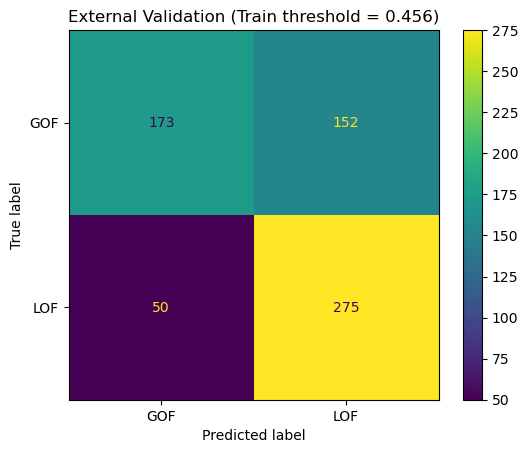

              precision    recall  f1-score   support

         GOF       0.78      0.53      0.63       325
         LOF       0.64      0.85      0.73       325

    accuracy                           0.69       650
   macro avg       0.71      0.69      0.68       650
weighted avg       0.71      0.69      0.68       650


Calibrated CV AUC: 0.896 ± 0.007


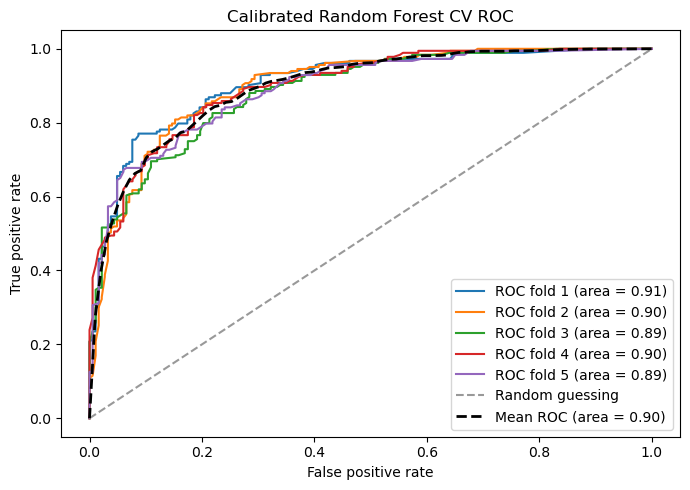

Leakage-Free CV ROC AUC : 0.893 ± 0.012


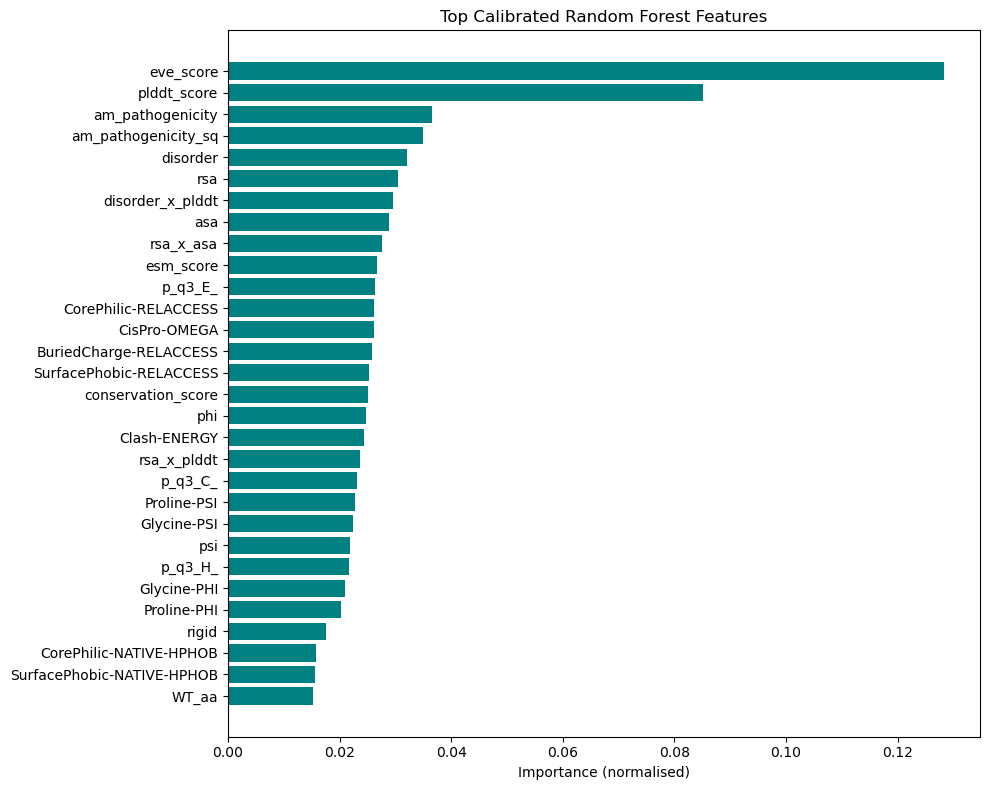


Top 10 features:
            Feature  Importance
          eve_score    0.128319
        plddt_score    0.085159
   am_pathogenicity    0.036635
am_pathogenicity_sq    0.034970
           disorder    0.032151
                rsa    0.030436
   disorder_x_plddt    0.029548
                asa    0.028861
          rsa_x_asa    0.027536
          esm_score    0.026730


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

# ── 1. Split Checks ──────────────────────────────────────────────────────────
# Ensure X_train, y_train_orig, X_test, y_test_orig are already defined
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── 2. RFECV Feature Selection (Strictly on Train) ───────────────────────────
print("Running RFECV for feature selection on Training Set...")
rf_rfe = RandomForestClassifier(n_estimators=300, random_state=42)
rfecv_rf = RFECV(
    estimator=rf_rfe,
    step=1,
    min_features_to_select=1,
    cv=cv_strategy,
    scoring="roc_auc",
    n_jobs=-1,
)
rfecv_rf.fit(X_train, y_train_orig)

rf_features = list(rfecv_rf.get_feature_names_out())
X_train_selected_rf = X_train[rf_features]
X_test_selected_rf  = X_test[rf_features]
print(f"RF optimal features: {rfecv_rf.n_features_} → {rf_features}")

# Plot RFECV curve
n_features  = len(rfecv_rf.cv_results_["mean_test_score"])
mean_scores = rfecv_rf.cv_results_["mean_test_score"]
std_scores  = rfecv_rf.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)

plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--', label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 2, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC")
plt.title("RF RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("RF_3class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV Hyperparameter Tuning ───────────────────────────────────
param_grid = {
    'n_estimators': [10, 20, 30, 50, 100, 200, 300],
    'max_depth':    [1, 2, 3, 10, None]
}
gs = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strategy,
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected_rf, y_train_orig)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")

# ── 4. Calibrate Probabilities on Training Set ──────────────────────────────
raw_model = RandomForestClassifier(**best_params, random_state=42)
calibrated_model = CalibratedClassifierCV(raw_model, method='isotonic', cv=cv_strategy)
calibrated_model.fit(X_train_selected_rf, y_train_orig)

# ── 5. Optimal Threshold Selection (STRICTLY ON TRAIN OOF PREDICTIONS) ──────
# Generate Out-Of-Fold calibrated probabilities to find optimal threshold without leakage
oof_proba_train = cross_val_predict(
    calibrated_model, X_train_selected_rf, y_train_orig, cv=cv_strategy, method='predict_proba'
)[:, 1]

fpr_tr, tpr_tr, thr_tr = roc_curve(y_train_orig, oof_proba_train, pos_label=1)
j_idx = np.argmax(tpr_tr - fpr_tr)
best_thr = thr_tr[j_idx]

print(f"\n★ Optimal Threshold determined from Train OOF (Youden-J): {best_thr:.4f}")
print(f"  Train OOF Sensitivity (LOF recall) : {tpr_tr[j_idx]:.3f}")
print(f"  Train OOF Specificity (GOF recall) : {1 - fpr_tr[j_idx]:.3f}")

# ── 6. Probability Distribution Plot (Train OOF vs Test) ───────────────────
proba_test_cal = calibrated_model.predict_proba(X_test_selected_rf)[:, 1]
fpr_t, tpr_t, _ = roc_curve(y_test_orig, proba_test_cal, pos_label=1)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[y_test_orig == 0], bins=30, alpha=0.6, label='GOF', color='purple')
plt.hist(proba_test_cal[y_test_orig == 1], bins=30, alpha=0.6, label='LOF', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Train Thr ({best_thr:.2f})')
plt.xlabel('Calibrated probability of LOF')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue', label='Test ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (Pure Holdout)')
plt.legend()
plt.tight_layout()
plt.savefig("RF_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Test Set Evaluation: Default Threshold (0.5) ─────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(y_test_orig, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated RF model")
plt.savefig("RF_bestModel_ConfusionMatrix_default.png", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_default, target_names=['GOF', 'LOF']))

# ── 8. Test Set Evaluation: Applied Train-Derived Threshold ───────────────
print(f"\n--- Test Set: Applied Train-Derived Threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(y_test_orig, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"Train-Derived Threshold = {best_thr:.3f} on Test Set")
plt.savefig("RF_bestModel_ConfusionMatrix_OptThr.png", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_opt, target_names=['GOF', 'LOF']))

# ── 9. External Validation (BLIND — threshold fixed from train set) ────────
rf_val_fresh = test_val_df.copy() # <-- THE VAULT 
target_rf = rf_val_fresh['goflof']
rf_val_fresh = clean_cols(rf_val_fresh)
rf_val_fresh = feature_engineering(rf_val_fresh)

X_val_rf = rf_val_fresh[rf_features]
proba_val_cal = calibrated_model.predict_proba(X_val_rf)[:, 1]

auc_rf_val = roc_auc_score(target_rf, proba_val_cal)
print(f"\n★ RF External Validation AUC (calibrated): {auc_rf_val:.4f}")

y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_rf, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"External Validation (Train threshold = {best_thr:.3f})")
plt.savefig("RF_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.show()
print(classification_report(target_rf, y_pred_val, target_names=['GOF', 'LOF']))

# ── 10. CV ROC Folds (Calibrated Pipeline) ─────────────────────────────────
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_strategy.split(X_train_selected_rf, y_train_orig)):
    # Fit calibrated model on training fold only
    fold_base = RandomForestClassifier(**best_params, random_state=42)
    fold_calibrated = CalibratedClassifierCV(fold_base, method='isotonic', cv=3)
    fold_calibrated.fit(X_train_selected_rf.iloc[tr], y_train_orig.iloc[tr])
    
    probas = fold_calibrated.predict_proba(X_train_selected_rf.iloc[te])
    fpr, tpr, _ = roc_curve(y_train_orig.iloc[te], probas[:, 1], pos_label=1)
    
    mean_tpr += np.interp(mean_fpr, fpr, tpr)
    fold_auc  = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= cv_strategy.get_n_splits()
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCalibrated CV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1], [0, 1], linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr, mean_tpr, 'k--', lw=2, label=f'Mean ROC (area = {mean_auc:.2f})')
plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Calibrated Random Forest CV ROC')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig("RF_bestModel_AUC.png", dpi=600)
plt.show()

# ── 11. Leakage-Free CV Metrics Pipeline ───────────────────────────────────
# Wrap entire selection & model into pipeline to avoid selection bias in CV scores
full_cv_pipeline = Pipeline([
    ('rfecv', RFECV(estimator=rf_rfe, cv=3, scoring='roc_auc')),
    ('calibrated_rf', CalibratedClassifierCV(
        estimator=RandomForestClassifier(**best_params, random_state=42), 
        method='isotonic', cv=3
    ))
])

scores1 = cross_val_score(full_cv_pipeline, X_train, y_train_orig, scoring='roc_auc', cv=cv_strategy)
print(f"Leakage-Free CV ROC AUC : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")

# ── 12. Feature Importance ──────────────────────────────────────────────────
importances_list = [
    clf.estimator.feature_importances_ for clf in calibrated_model.calibrated_classifiers_
]
importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()

feature_importance_df = pd.DataFrame({'Feature': X_train_selected_rf.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
n_top = min(30, len(feature_importance_df))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top Calibrated Random Forest Features')
plt.tight_layout()
plt.savefig("RF_bestModel_FeatureImportance.png", dpi=600)
plt.show()

print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

>2. RandomForest Model

Running RFECV for feature selection...
RF optimal features: 66 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'BuriedCharge-BOOL', 'BuriedCharge-MUTANT-CHARGE', 'CisPro-OMEGA', 'Clash-ENERGY', 'Clash-BOOL', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-NATIVE-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-BOOL', 'HBonds-ENERGY', 'Proline-NATIVE-ENERGY', 'Proline-PHI', 'Proline-MUTANT-ENERGY', 'Proline-PSI', 'SSGeom-BOOL', 'SurfacePhobic-MUTANT-HPHOB', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'acetylation', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'buried', 'exposed', 'rigid', 'flexible', 'buried_rigid', 'charge_change',

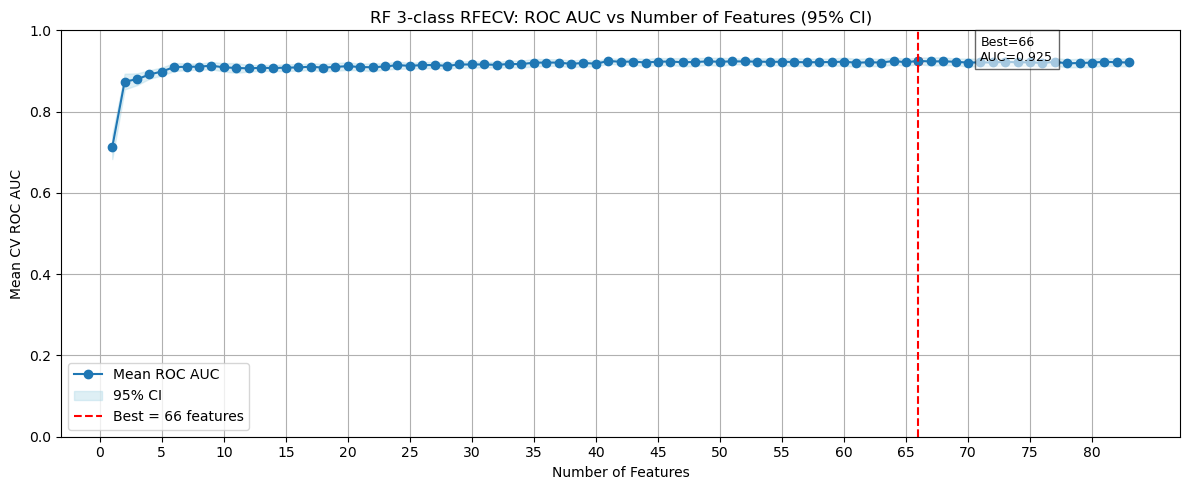

Best Parameters : {'max_depth': None, 'n_estimators': 300}
Best CV ROC AUC : 0.925
Train ROC AUC   : 1.000

Calibrated prob range: [0.000, 1.000]
Mean prob (should be ~0.5): 0.561

Optimal threshold (Youden J on TEST set, calibrated): 0.6080
  Sensitivity (LOF recall) : 0.743
  Specificity (GOF recall) : 0.731


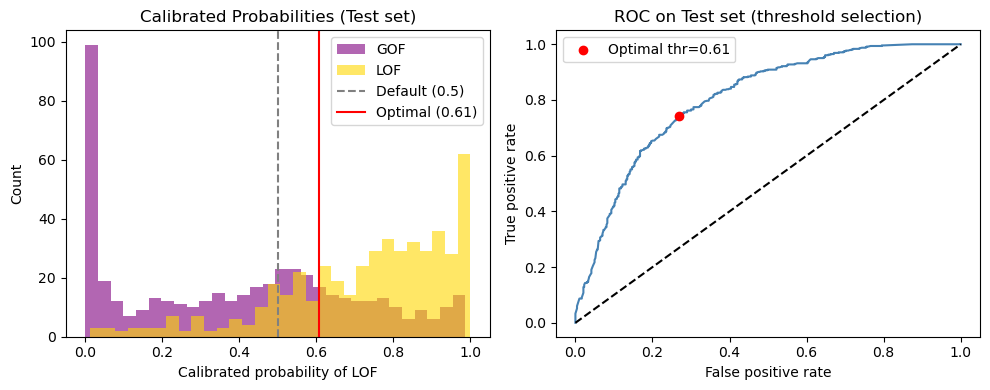


--- Test Set: Default threshold (0.5) ---


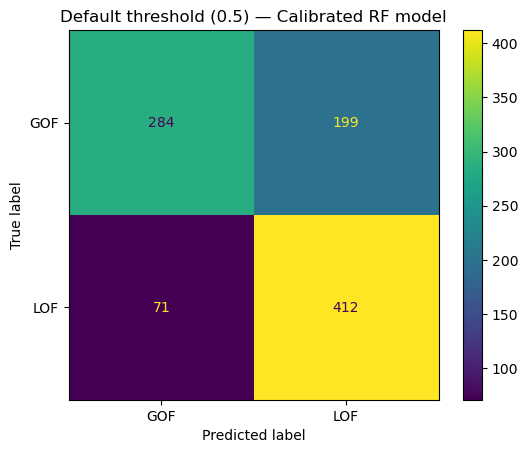

              precision    recall  f1-score   support

         GOF       0.80      0.59      0.68       483
         LOF       0.67      0.85      0.75       483

    accuracy                           0.72       966
   macro avg       0.74      0.72      0.72       966
weighted avg       0.74      0.72      0.72       966


--- Test Set: Optimal threshold (0.608) ---


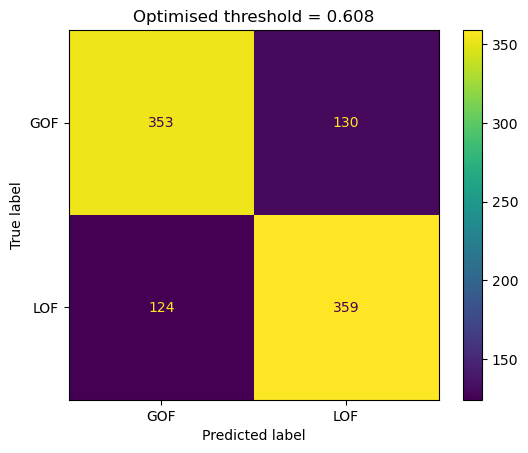

              precision    recall  f1-score   support

         GOF       0.74      0.73      0.74       483
         LOF       0.73      0.74      0.74       483

    accuracy                           0.74       966
   macro avg       0.74      0.74      0.74       966
weighted avg       0.74      0.74      0.74       966


★ RF Validation AUC (calibrated): 0.7957


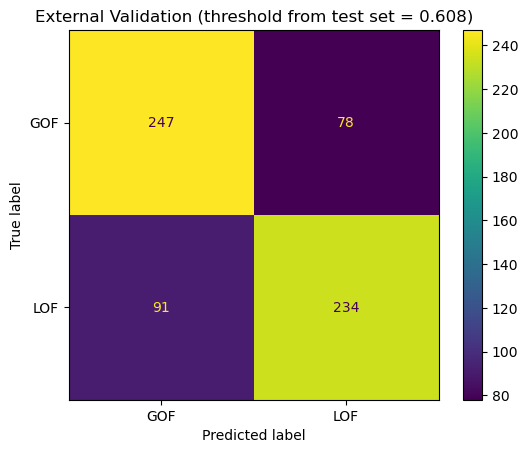

              precision    recall  f1-score   support

         GOF       0.73      0.76      0.75       325
         LOF       0.75      0.72      0.73       325

    accuracy                           0.74       650
   macro avg       0.74      0.74      0.74       650
weighted avg       0.74      0.74      0.74       650


CV AUC: 0.924 ± 0.009


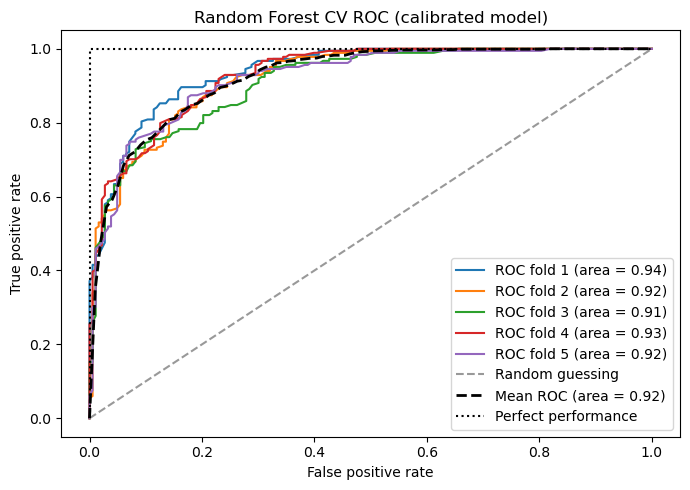

cv ROC AUC   : 0.927 ± 0.013
cv precision : 0.840 ± 0.012
cv recall    : 0.839 ± 0.012
cv f1        : 0.839 ± 0.012


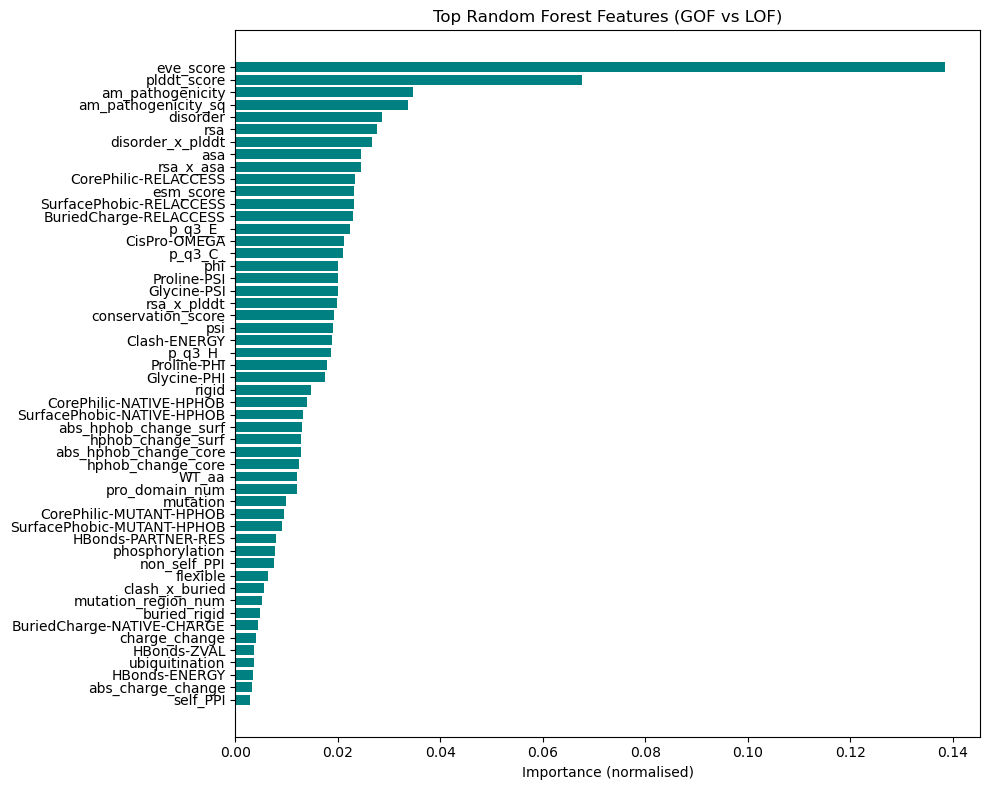


Top 10 features:
             Feature  Importance
           eve_score    0.138426
         plddt_score    0.067581
    am_pathogenicity    0.034642
 am_pathogenicity_sq    0.033617
            disorder    0.028670
                 rsa    0.027671
    disorder_x_plddt    0.026721
                 asa    0.024582
           rsa_x_asa    0.024563
CorePhilic-RELACCESS    0.023411


['RF_bestModel_Calibrated.pkl']

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.feature_selection import RFECV

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

# ── 1. Split ──────────────────────────────────────────────────────────────────
# X_train, y_train_orig = X_train.reset_index(drop=True), y_train_orig.reset_index(drop=True)
X_train, y_train_orig = X_train, y_train_orig
# X_train, X_test, y_train, y_test = train_test_split(X_train, y_train_orig, test_size=0.2, random_state=42, stratify=y_train_orig)

# ── 2. Feature selection (from RFECV) ────────────────────────────────────────

# ── 2. RFECV Feature Selection ────────────────────────────────────────────────
print("Running RFECV for feature selection...")
rf_rfe    = RandomForestClassifier(n_estimators=300, random_state=42)
rfecv_rf  = RFECV(
    estimator=rf_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",           #
    n_jobs=-1,
)
rfecv_rf.fit(X_train, y_train_orig)

rf_features      = list(rfecv_rf.get_feature_names_out())
X_train_selected_rf = X_train[rf_features]
X_test_selected_rf  = X_test[rf_features]
print(f"RF optimal features: {rfecv_rf.n_features_} → {rf_features}")

# Plot RFECV curve with 95% CI
n_features  = len(rfecv_rf.cv_results_["mean_test_score"])
mean_scores = rfecv_rf.cv_results_["mean_test_score"]
std_scores  = rfecv_rf.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)

plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC")
plt.title("RF 3-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("RF_3class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV for hyperparameter tuning ─────────────────────────────────
param_grid = {
    'n_estimators': [10, 20, 30, 50, 100, 200, 300],
    'max_depth':    [1, 2, 3, 10, None]
}
gs = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',           # changed from accuracy → roc_auc
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected_rf, y_train_orig)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
# Random Forest probabilities are often poorly calibrated (overly confident)
# Isotonic regression corrects this
raw_model_rf = RandomForestClassifier(**best_params, random_state=42)
calibrated_model_rf = CalibratedClassifierCV(raw_model_rf, method='isotonic', cv=5)
calibrated_model_rf.fit(X_train_selected_rf, y_train_orig)

proba_test_cal = calibrated_model_rf.predict_proba(X_test_selected_rf)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Optimal threshold on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(y_test_orig, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (LOF recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (GOF recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check) ──────────────────────────
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[y_test_orig == 0], bins=30, alpha=0.6, label='GOF', color='purple')
plt.hist(proba_test_cal[y_test_orig == 1], bins=30, alpha=0.6, label='LOF', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of LOF')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("RF_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Test set: Default threshold (0.5) ─────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(y_test_orig, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated RF model")
plt.savefig("RF_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_default, target_names=['GOF', 'LOF']))

# ── 8. Test set: Optimal (Youden-J) threshold ────────────────────────────────
print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(y_test_orig, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("RF_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_OptThr_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_opt, target_names=['GOF', 'LOF']))

# ── 9. External Validation (BLIND — threshold fixed from test set) ────────────
rf_val_fresh = test_val_df.copy() # <-- THE VAULT 
target_rf  = rf_val_fresh['goflof']
# add feature engineering to validation set and clean columns
rf_val_fresh = clean_cols(rf_val_fresh)
rf_val_fresh = feature_engineering(rf_val_fresh)

X_val_rf   = rf_val_fresh[rf_features]
proba_val_cal = calibrated_model_rf.predict_proba(X_val_rf)[:, 1]

# AUC on external validation
auc_rf_val = roc_auc_score(target_rf, proba_val_cal)
print(f"\n★ RF Validation AUC (calibrated): {auc_rf_val:.4f}")

# Apply threshold from test set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_rf, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("RF_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_rf, y_pred_val, target_names=['GOF', 'LOF']))

# ── 10. CV ROC folds ──────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected_rf, y_train_orig))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = RandomForestClassifier(**best_params, random_state=42)
    fold_model.fit(X_train_selected_rf.iloc[tr], y_train_orig.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected_rf.iloc[te])
    fpr, tpr, _ = roc_curve(y_train_orig.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Random Forest CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("RF_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_AUC_miRNA_HG.svg", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 11. CV metrics ────────────────────────────────────────────────────────────
fresh_rf = RandomForestClassifier(**best_params, random_state=42)
scores1  = cross_val_score(fresh_rf, X_train_selected_rf, y_train_orig, scoring='roc_auc', cv=5)
scores2  = cross_val_score(fresh_rf, X_train_selected_rf, y_train_orig,
                           scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3  = cross_val_score(fresh_rf, X_train_selected_rf, y_train_orig,
                           scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4  = cross_val_score(fresh_rf, X_train_selected_rf, y_train_orig,
                           scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 12. Feature importance (averaged across calibrated folds) ─────────────────
importances_list = []
for calibrated_clf in calibrated_model_rf.calibrated_classifiers_:
    importances_list.append(calibrated_clf.estimator.feature_importances_)

importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()   # normalise to 0–1

feature_importance_df = pd.DataFrame({'Feature': X_train_selected_rf.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top Random Forest Features (GOF vs LOF)')
plt.tight_layout()
plt.savefig("RF_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()

print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

# save model and feature importance for future use
import joblib
joblib.dump(calibrated_model_rf, "RF_bestModel_Calibrated.pkl")


Cracking open the Random Forest model with SHAP...


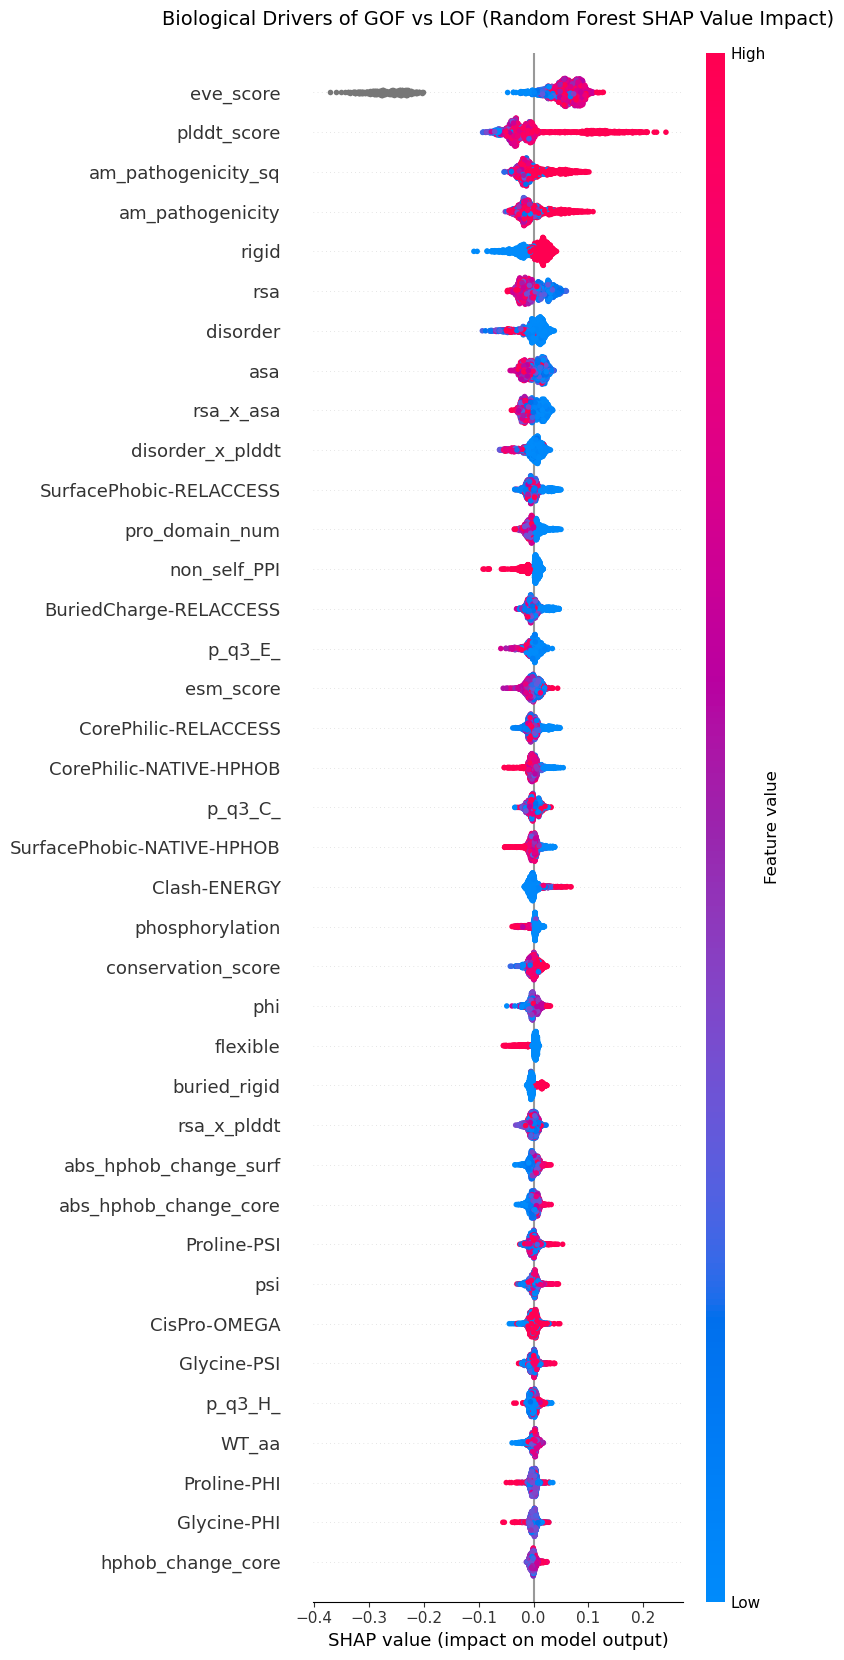

In [6]:
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

print("Cracking open the Random Forest model with SHAP...")

# Filter best_params to only include parameters that RandomForestClassifier accepts
rf_valid_params = {
    k: v for k, v in best_params.items() 
    if k in RandomForestClassifier().get_params()
}

# Fit a plain Random Forest model for explanation
shap_model = RandomForestClassifier(
    **rf_valid_params,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
shap_model.fit(X_train_selected_rf, y_train_orig)

# Use TreeExplainer for Random Forest
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_train_selected_rf)

# Handle 3D arrays vs list outputs across SHAP versions for binary classification
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
elif hasattr(shap_values, "shape") and len(shap_values.shape) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

# Generate the Summary Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_class1, X_train_selected_rf, max_display=38, show=False)
plt.title("Biological Drivers of GOF vs LOF (Random Forest SHAP Value Impact)", fontsize=14, pad=20)
plt.tight_layout()
plt.savefig("RF_SHAP_summary_plot.png", dpi=600)
plt.show()

> 2. XGB MODEL

XGB RFECV optimal features: 36 → ['WT_aa', 'BuriedCharge-RELACCESS', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-NATIVE-HPHOB', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-ENERGY', 'SSGeom-BOOL', 'plddt_score', 'rsa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'acetylation', 'sumoylation', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'charge_change', 'abs_hphob_change_core', 'proline_energy_change', 'disorder_x_plddt', 'clash_x_buried', 'hbonds_x_buried']


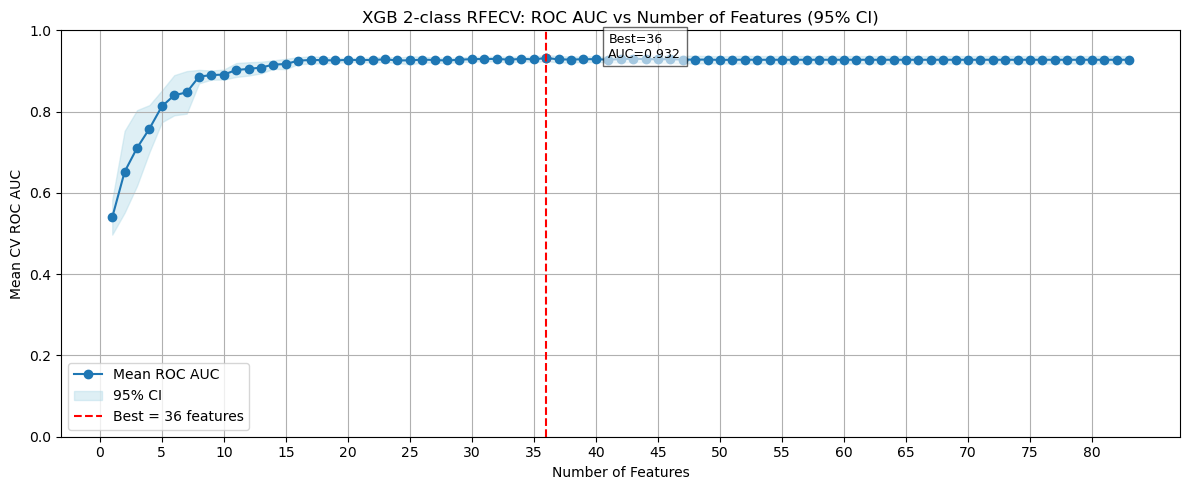

Best Parameters : {'colsample_bytree': 0.55, 'learning_rate': 0.15, 'max_depth': 7, 'n_estimators': 240, 'subsample': 0.95}
Best CV ROC AUC : 0.935
Train ROC AUC   : 1.000

Calibrated prob range: [0.000, 1.000]
Mean prob (should be ~0.5): 0.543

Optimal threshold (Youden J on TEST set, calibrated): 0.5376
  Sensitivity (LOF recall) : 0.739
  Specificity (GOF recall) : 0.675


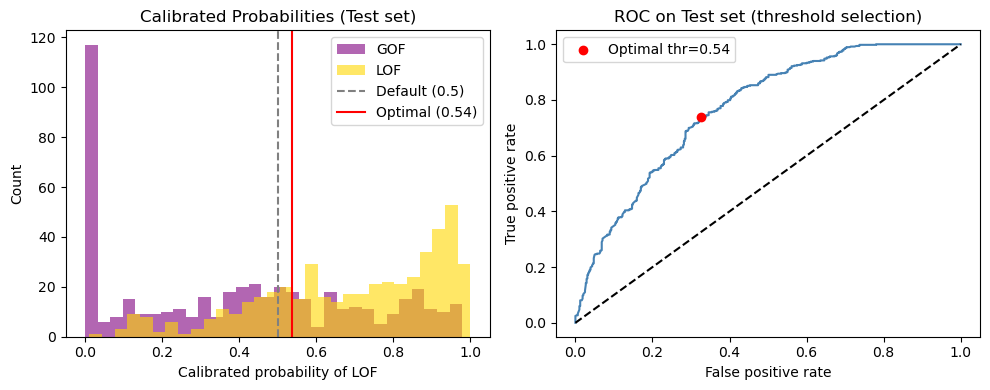


--- Test Set: Default threshold (0.5) ---


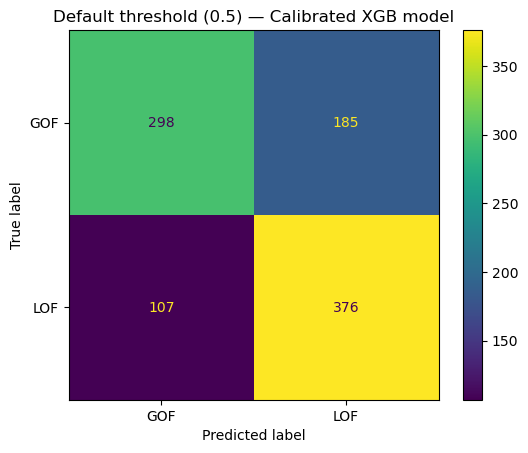

              precision    recall  f1-score   support

         GOF       0.74      0.62      0.67       483
         LOF       0.67      0.78      0.72       483

    accuracy                           0.70       966
   macro avg       0.70      0.70      0.70       966
weighted avg       0.70      0.70      0.70       966


--- Test Set: Optimal threshold (0.538) ---


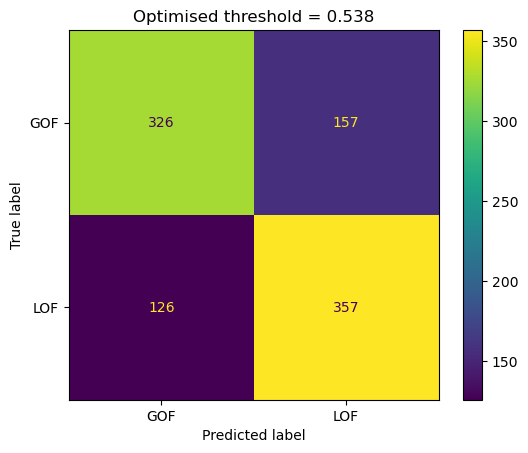

              precision    recall  f1-score   support

         GOF       0.72      0.67      0.70       483
         LOF       0.69      0.74      0.72       483

    accuracy                           0.71       966
   macro avg       0.71      0.71      0.71       966
weighted avg       0.71      0.71      0.71       966


★ XGBoost Validation AUC (calibrated): 0.8087


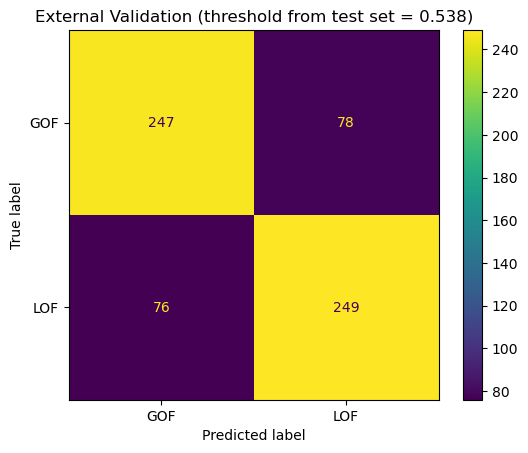

              precision    recall  f1-score   support

         GOF       0.76      0.76      0.76       325
         LOF       0.76      0.77      0.76       325

    accuracy                           0.76       650
   macro avg       0.76      0.76      0.76       650
weighted avg       0.76      0.76      0.76       650


CV AUC: 0.934 ± 0.008


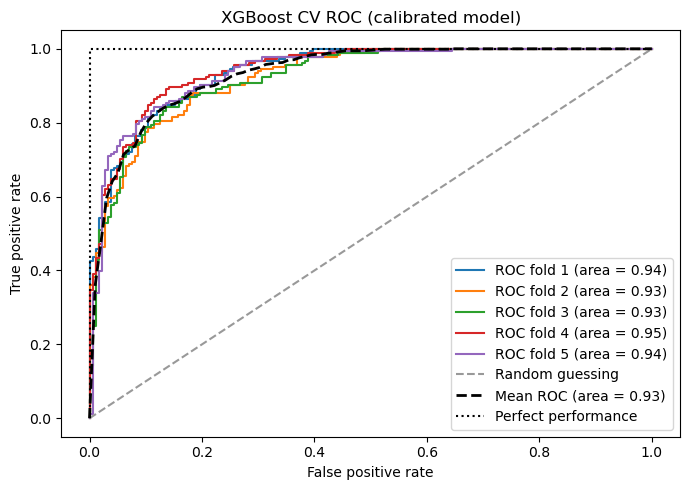

cv ROC AUC   : 0.936 ± 0.007
cv precision : 0.854 ± 0.010
cv recall    : 0.853 ± 0.010
cv f1        : 0.853 ± 0.010


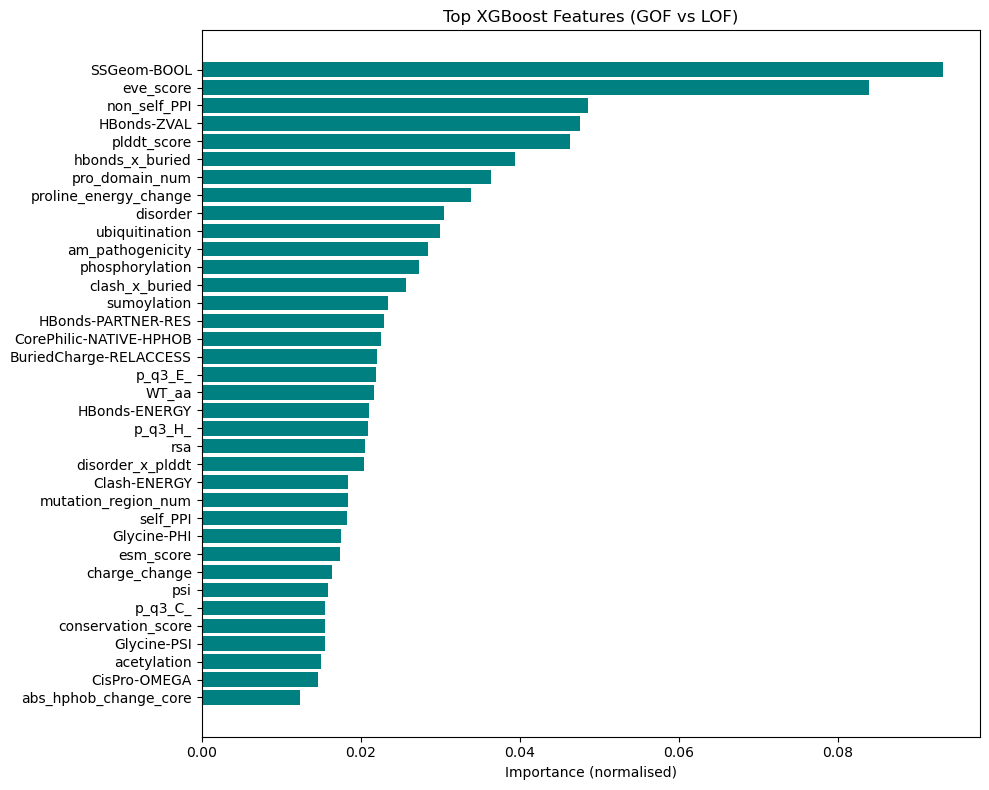


Top 10 features:
              Feature  Importance
          SSGeom-BOOL    0.093243
            eve_score    0.083967
         non_self_PPI    0.048642
          HBonds-ZVAL    0.047589
          plddt_score    0.046275
      hbonds_x_buried    0.039380
       pro_domain_num    0.036414
proline_energy_change    0.033866
             disorder    0.030478
       ubiquitination    0.029939


['xgb_bestModel_Calibrated.pkl']

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

# ── 1. Split ──────────────────────────────────────────────────────────────────


# ── 2. Feature selection (from RFECV) ────────────────────────────────────────
xgb_rfe = xgb.XGBClassifier(n_estimators=300, random_state=42)
rfecv_xgb = RFECV(
    estimator=xgb_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
rfecv_xgb.fit(X_train, y_train_orig) 
xgb_features      = list(rfecv_xgb.get_feature_names_out())
X_train_selected_xgb = X_train[xgb_features]
X_test_selected_xgb  = X_test[xgb_features]
print(f"XGB RFECV optimal features: {rfecv_xgb.n_features_} → {xgb_features}")  
#plot RFECV curve with 95% CI
n_features  = len(rfecv_xgb.cv_results_["mean_test_score"])
mean_scores = rfecv_xgb.cv_results_["mean_test_score"]
std_scores  = rfecv_xgb.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)    
plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC")
plt.title("XGB 2-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("XGB_2class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV for hyperparameter tuning ─────────────────────────────────
param_grid = {
    'n_estimators':  [240],
    'max_depth':     [7],
    'learning_rate': [0.15],
    'subsample':     [0.95],
    'colsample_bytree': [0.55]
}
gs = GridSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',           # changed from accuracy → roc_auc
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected_xgb, y_train_orig)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model_xgb = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
calibrated_model_xgb = CalibratedClassifierCV(raw_model_xgb, method='isotonic', cv=5)
calibrated_model_xgb.fit(X_train_selected_xgb, y_train_orig)

proba_test_cal = calibrated_model_xgb.predict_proba(X_test_selected_xgb)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Optimal threshold on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(y_test_orig, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (LOF recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (GOF recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check) ──────────────────────────
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[y_test_orig == 0], bins=30, alpha=0.6, label='GOF', color='purple')
plt.hist(proba_test_cal[y_test_orig == 1], bins=30, alpha=0.6, label='LOF', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of LOF')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("xgb_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Test set: Default threshold (0.5) ─────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(y_test_orig, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated XGB model")
plt.savefig("xgb_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_default, target_names=['GOF', 'LOF']))

# ── 8. Test set: Optimal (Youden-J) threshold ────────────────────────────────
print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(y_test_orig, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("xgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_opt, target_names=['GOF', 'LOF']))

# ── 9. External Validation (BLIND — threshold fixed from test set) ────────────
xgb_val_fresh = test_val_df.copy() # make a copy of the validation set to avoid modifying the original
#
target_xgb    = xgb_val_fresh['goflof']
# make feature engineering on & clean the validation set
xgb_val_fresh = clean_cols(xgb_val_fresh)
xgb_val_fresh = feature_engineering(xgb_val_fresh)

X_val_xgb     = xgb_val_fresh[xgb_features]
proba_val_cal = calibrated_model_xgb.predict_proba(X_val_xgb)[:, 1]

# AUC on external validation
auc_xgb_val = roc_auc_score(target_xgb, proba_val_cal)
print(f"\n★ XGBoost Validation AUC (calibrated): {auc_xgb_val:.4f}")

# Apply threshold from test set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_xgb, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("xgb_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_xgb, y_pred_val, target_names=['GOF', 'LOF']))

# ── 10. CV ROC folds ──────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected_xgb, y_train_orig))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
    fold_model.fit(X_train_selected_xgb.iloc[tr], y_train_orig.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected_xgb.iloc[te])
    fpr, tpr, _ = roc_curve(y_train_orig.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('XGBoost CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("xgb_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_AUC_miRNA_HG.svg", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 11. CV metrics ────────────────────────────────────────────────────────────
fresh_xgb = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
scores1 = cross_val_score(fresh_xgb, X_train_selected_xgb, y_train_orig, scoring='roc_auc', cv=5)
scores2 = cross_val_score(fresh_xgb, X_train_selected_xgb, y_train_orig,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_xgb, X_train_selected_xgb, y_train_orig,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_xgb, X_train_selected_xgb, y_train_orig,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 12. Feature importance (averaged across calibrated folds, normalised) ─────
importances_list = []
for calibrated_clf in calibrated_model_xgb.calibrated_classifiers_:
    importances_list.append(calibrated_clf.estimator.feature_importances_)

importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()   # normalise to 0–1

feature_importance_df = pd.DataFrame({'Feature': X_train_selected_xgb.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top XGBoost Features (GOF vs LOF)')
plt.tight_layout()
plt.savefig("xgb_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()

print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))
# save model and feature importance for future use
import joblib
joblib.dump(calibrated_model_xgb, "xgb_bestModel_Calibrated.pkl")

Novel genes validation


Confusion Matrix for Novel Test Genes:
[[326 157]
 [126 357]]
              precision    recall  f1-score   support

         GOF       0.72      0.67      0.70       483
         LOF       0.69      0.74      0.72       483

    accuracy                           0.71       966
   macro avg       0.71      0.71      0.71       966
weighted avg       0.71      0.71      0.71       966



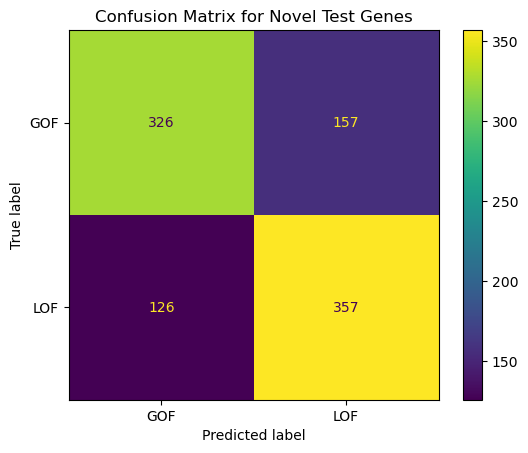

Novel Test Genes AUC: 0.771

Confusion Matrix for Novel Validation Genes:
[[ 44  29]
 [ 43 139]]
              precision    recall  f1-score   support

         GOF       0.51      0.60      0.55        73
         LOF       0.83      0.76      0.79       182

    accuracy                           0.72       255
   macro avg       0.67      0.68      0.67       255
weighted avg       0.74      0.72      0.72       255



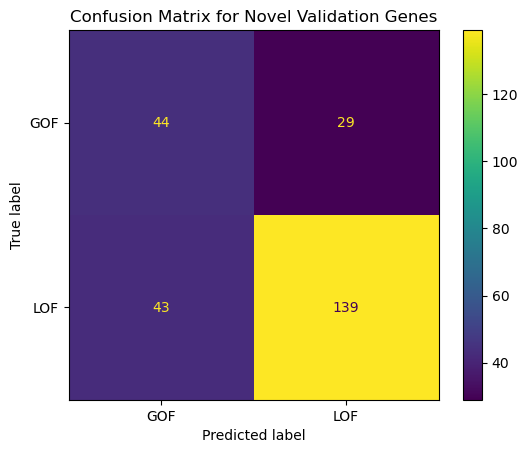

Novel Validation Genes AUC: 0.710

Confusion Matrix for Non-Novel Validation Genes:
[[203  49]
 [ 33 110]]
              precision    recall  f1-score   support

         GOF       0.86      0.81      0.83       252
         LOF       0.69      0.77      0.73       143

    accuracy                           0.79       395
   macro avg       0.78      0.79      0.78       395
weighted avg       0.80      0.79      0.79       395



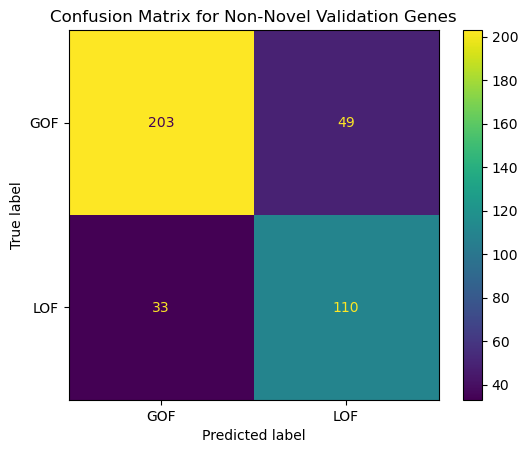

Non-Novel Validation Genes AUC: 0.842


In [19]:
# Get genes that are in training data and genes that are in test and validation data
train_genes = {idx.split('_')[0] for idx in X_train_selected_xgb.index.astype(str)}
test_genes = {idx.split('_')[0] for idx in X_test_selected_xgb.index.astype(str)}
validation_genes = {idx.split('_')[0] for idx in X_val_xgb.index.astype(str)}

# ---------------------------------------------------------
# Step 1: TEST SET
# ---------------------------------------------------------

# Merge test predictions with the original test dataframe
test_results_df = y_test_orig.to_frame(name='True_Label').copy()
test_results_df['Predicted_Label'] = y_pred_opt
test_results_df['Predicted_Prob'] = proba_test_cal
test_results_df['Gene'] = test_results_df.index.astype(str).str.split('_').str[0]

# A. Novel test genes
novel_test_genes_df = test_results_df[~test_results_df['Gene'].isin(train_genes)]  # 34

if not novel_test_genes_df.empty:
    novel_y_true = novel_test_genes_df['True_Label']
    novel_y_pred = novel_test_genes_df['Predicted_Label']
    novel_y_prob = novel_test_genes_df['Predicted_Prob']

    novel_cm = confusion_matrix(novel_y_true, novel_y_pred)
    print("\nConfusion Matrix for Novel Test Genes:")
    print(novel_cm)
    print(classification_report(novel_y_true, novel_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(novel_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Novel Test Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NovelTestGenes.png", dpi=600)
    plt.show()

    if novel_y_true.nunique() == 2:
        novel_auc = roc_auc_score(novel_y_true, novel_y_prob)
        print(f"Novel Test Genes AUC: {novel_auc:.3f}")

# B. Non-novel test genes
not_novel_test_genes_df = test_results_df[test_results_df['Gene'].isin(train_genes)]  # 526

if not not_novel_test_genes_df.empty:
    not_novel_y_true = not_novel_test_genes_df['True_Label']
    not_novel_y_pred = not_novel_test_genes_df['Predicted_Label']
    not_novel_y_prob = not_novel_test_genes_df['Predicted_Prob']

    not_novel_cm = confusion_matrix(not_novel_y_true, not_novel_y_pred)
    print("\nConfusion Matrix for Non-Novel Test Genes:")
    print(not_novel_cm)
    print(classification_report(not_novel_y_true, not_novel_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(not_novel_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Non-Novel Test Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NonNovelTestGenes.png", dpi=600)
    plt.show()

    if not_novel_y_true.nunique() == 2:
        not_novel_auc = roc_auc_score(not_novel_y_true, not_novel_y_prob)
        print(f"Non-Novel Test Genes AUC: {not_novel_auc:.3f}")

# ---------------------------------------------------------
# Step 2: VALIDATION SET
# ---------------------------------------------------------

validation_results_df = target_xgb.to_frame(name='True_Label').copy()
validation_results_df['Predicted_Label'] = y_pred_val
validation_results_df['Predicted_Prob'] = proba_val_cal
validation_results_df['Gene'] = validation_results_df.index.astype(str).str.split('_').str[0]

# A. Novel validation genes
novel_validation_genes_df = validation_results_df[~validation_results_df['Gene'].isin(train_genes)]  # 34

if not novel_validation_genes_df.empty:
    novel_val_y_true = novel_validation_genes_df['True_Label']
    novel_val_y_pred = novel_validation_genes_df['Predicted_Label']
    novel_val_y_prob = novel_validation_genes_df['Predicted_Prob']

    novel_val_cm = confusion_matrix(novel_val_y_true, novel_val_y_pred)
    print("\nConfusion Matrix for Novel Validation Genes:")
    print(novel_val_cm)
    print(classification_report(novel_val_y_true, novel_val_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(novel_val_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Novel Validation Genes")
    plt.savefig("xgb_bestModel_ConfusionMatrix_NovelValidationGenes.png", dpi=600)
    plt.show()

    if novel_val_y_true.nunique() == 2:
        novel_val_auc = roc_auc_score(novel_val_y_true, novel_val_y_prob)
        print(f"Novel Validation Genes AUC: {novel_val_auc:.3f}")

# B. Non-novel validation genes
not_novel_validation_genes_df = validation_results_df[validation_results_df['Gene'].isin(train_genes)]  # 526

if not not_novel_validation_genes_df.empty:
    not_novel_val_y_true = not_novel_validation_genes_df['True_Label']
    not_novel_val_y_pred = not_novel_validation_genes_df['Predicted_Label']
    not_novel_val_y_prob = not_novel_validation_genes_df['Predicted_Prob']

    not_novel_val_cm = confusion_matrix(not_novel_val_y_true, not_novel_val_y_pred)
    print("\nConfusion Matrix for Non-Novel Validation Genes:")
    print(not_novel_val_cm)
    print(classification_report(not_novel_val_y_true, not_novel_val_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(not_novel_val_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Non-Novel Validation Genes")
    plt.savefig("xgb_bestModel_ConfusionMatrix_NonNovelValidationGenes.png", dpi=600)
    plt.show()

    if not_novel_val_y_true.nunique() == 2:
        not_novel_val_auc = roc_auc_score(not_novel_val_y_true, not_novel_val_y_prob)
        print(f"Non-Novel Validation Genes AUC: {not_novel_val_auc:.3f}")

Cracking open the XGBoost model with SHAP...


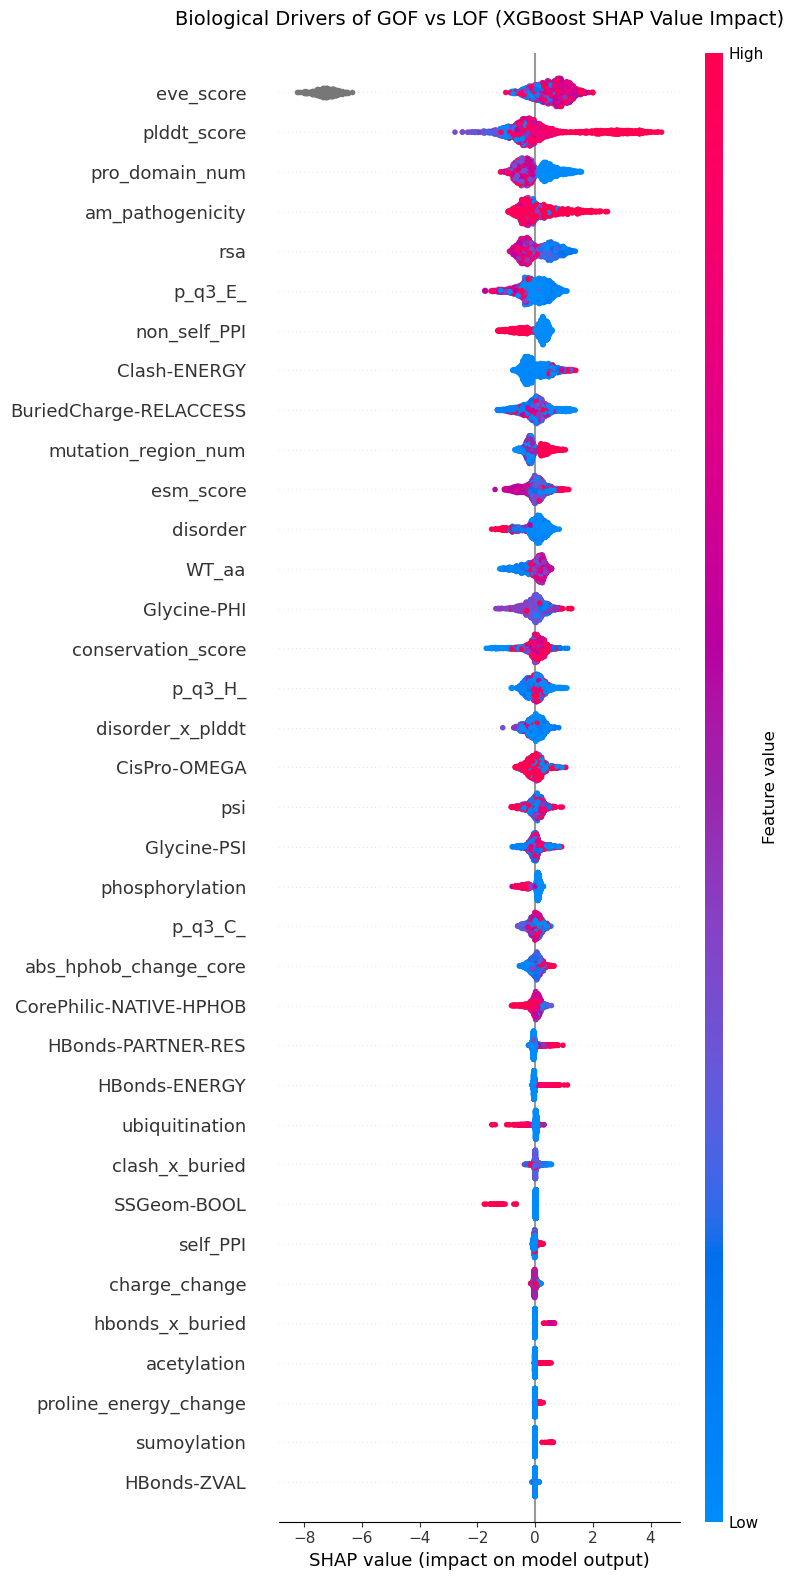

In [20]:
import shap
import matplotlib.pyplot as plt
import xgboost as xgb

print("Cracking open the XGBoost model with SHAP...")

# Filter best_params to only include parameters XGBoost accepts
xgb_valid_params = {
    k: v for k, v in best_params.items() 
    if k in xgb.XGBClassifier().get_params()
}

# Fit a plain XGBoost model for explanation
shap_model = xgb.XGBClassifier(
    **xgb_valid_params,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
shap_model.fit(X_train_selected_xgb, y_train_orig)

# Use TreeExplainer specifically optimized for XGBoost trees
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer(X_train_selected_xgb)

# Generate Summary Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train_selected_xgb, max_display=38, show=False)
plt.title("Biological Drivers of GOF vs LOF (XGBoost SHAP Value Impact)", fontsize=14, pad=20)
plt.tight_layout()
plt.savefig("XGB_SHAP_summary_plot.png", dpi=600)
plt.show()

In [18]:
# merge X_val_xgb with predicted values y_pred_val, and target_xgb with out messing up the indexes just put them side by side in a new dataframe
val_results_df = pd.DataFrame({
    'Predicted': y_pred_val,
    'Probability': proba_val_cal,
    'Actual': target_xgb
})

# merge val_results_df with X_val_xgb  on index new_hgnc_agg_ids
val_results_df_features = pd.merge(val_results_df, X_val_xgb, left_index=True, right_index=True)


> 3. LGBM MODEL

/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/

LGB optimal features: 34 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-PARTNER-RES', 'SSGeom-BOOL', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'pro_domain_num', 'mutation_region_num', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'hphob_change_core', 'abs_hphob_change_core', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt']


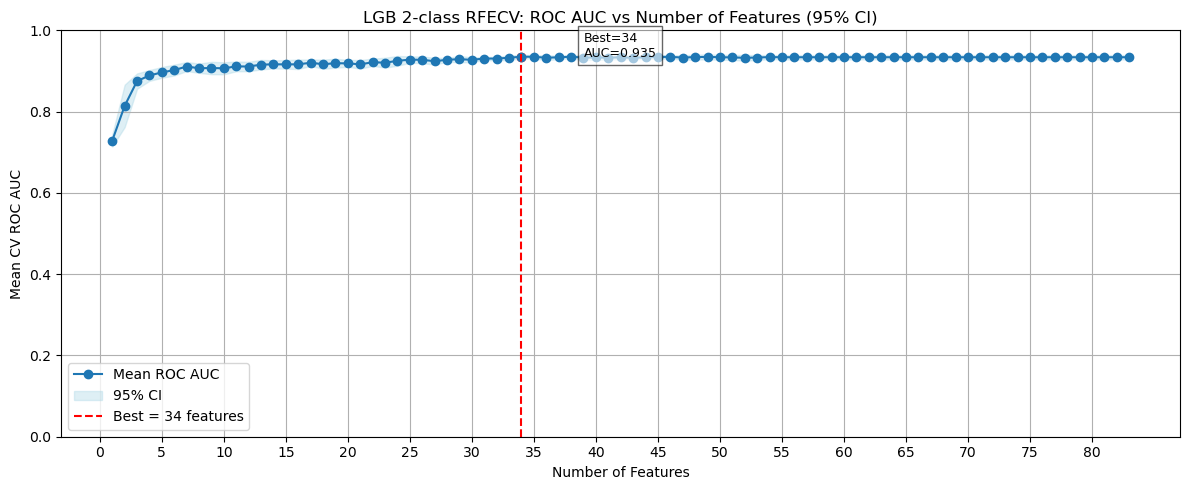

Fitting 5 folds for each of 128 candidates, totalling 640 fits
Best Parameters : {'learning_rate': 0.1, 'max_depth': 5, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 31, 'reg_alpha': 1, 'reg_lambda': 0.1}
Best CV ROC AUC : 0.932
Train ROC AUC   : 1.000

Calibrated prob range: [0.000, 1.000]
Mean prob (should be ~0.5): 0.536

Optimal threshold (Youden J on TEST set, calibrated): 0.4481
  Sensitivity (LOF recall) : 0.807
  Specificity (GOF recall) : 0.602


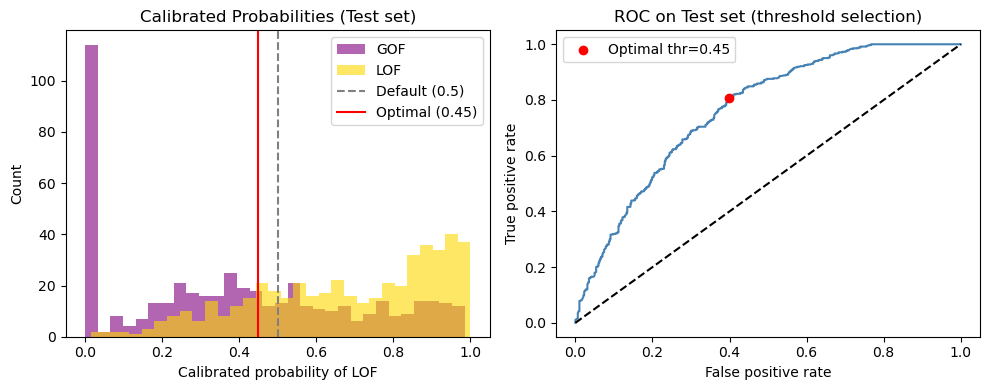


--- Test Set: Default threshold (0.5) ---


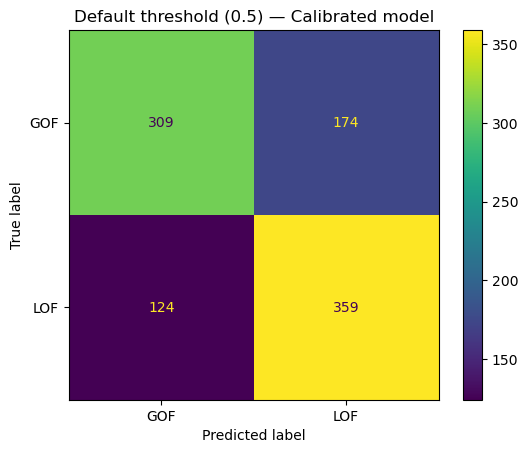

              precision    recall  f1-score   support

         GOF       0.71      0.64      0.67       483
         LOF       0.67      0.74      0.71       483

    accuracy                           0.69       966
   macro avg       0.69      0.69      0.69       966
weighted avg       0.69      0.69      0.69       966


--- Test Set: Optimal threshold (0.448) ---


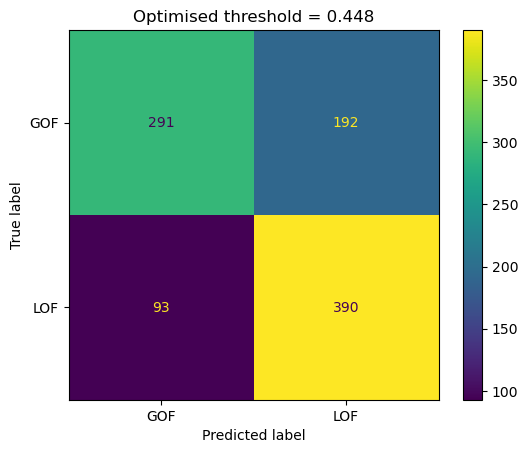

              precision    recall  f1-score   support

         GOF       0.76      0.60      0.67       483
         LOF       0.67      0.81      0.73       483

    accuracy                           0.70       966
   macro avg       0.71      0.70      0.70       966
weighted avg       0.71      0.70      0.70       966


★ LightGBM Validation AUC (calibrated): 0.8040


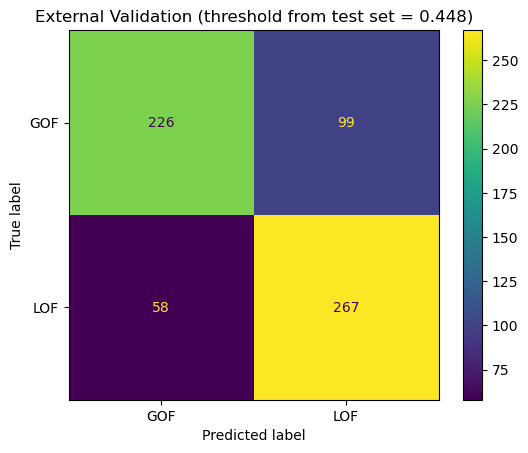

              precision    recall  f1-score   support

         GOF       0.80      0.70      0.74       325
         LOF       0.73      0.82      0.77       325

    accuracy                           0.76       650
   macro avg       0.76      0.76      0.76       650
weighted avg       0.76      0.76      0.76       650


CV AUC: 0.931 ± 0.010


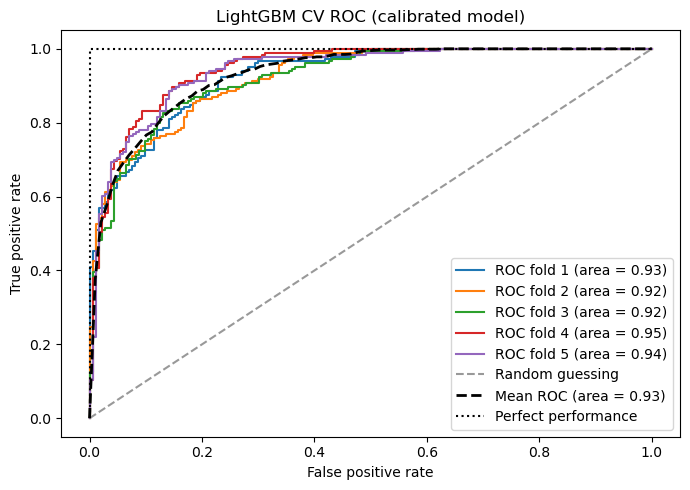

cv ROC AUC   : 0.931 ± 0.007
cv precision : 0.845 ± 0.008
cv recall    : 0.845 ± 0.008
cv f1        : 0.845 ± 0.008


['lgb_bestModel_Calibrated.pkl']

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_val_score
from sklearn.feature_selection import RFECV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.base import clone
import pandas as pd

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

# ── 1. Split ──────────────────────────────────────────────────────────────────


# ── 2. RFECV feature selection ────────────────────────────────────────────────
lgbm_rfe = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
rfecv_lgb = RFECV(
    estimator=lgbm_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
rfecv_lgb.fit(X_train, y_train_orig)
lgb_features = list(rfecv_lgb.get_feature_names_out())
print(f"LGB optimal features: {rfecv_lgb.n_features_} → {lgb_features}")

X_train_selected_lgb = X_train[lgb_features]
X_test_selected_lgb  = X_test[lgb_features]

# plot RFECV curve with 95% CI
n_features  = len(rfecv_lgb.cv_results_["mean_test_score"])
mean_scores = rfecv_lgb.cv_results_["mean_test_score"]          
std_scores  = rfecv_lgb.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))  # 95% confidence interval
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)        # index of best score (max AUC)
plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC") 
plt.title("LGB 2-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("LGB_2class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearch ─────────────────────────────────────────────────────────────
param_grid = {
    'n_estimators':  [100, 200],
    'max_depth':     [3, 5],
    'learning_rate': [0.1, 0.2],
    'num_leaves':    [31, 62],
    'reg_alpha':     [0.1, 1],
    'reg_lambda':    [0.1, 1],
    'min_child_samples': [10, 20]
}

gs = GridSearchCV(
    estimator=lgb.LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, verbose=1, return_train_score=True
)
gs.fit(X_train_selected_lgb, y_train_orig)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model_lgb = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                class_weight='balanced')
calibrated_model_lgb = CalibratedClassifierCV(raw_model_lgb, method='isotonic', cv=5)
calibrated_model_lgb.fit(X_train_selected_lgb, y_train_orig)

proba_test_cal = calibrated_model_lgb.predict_proba(X_test_selected_lgb)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Threshold search on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(y_test_orig, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (LOF recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (GOF recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check on TEST set) ──────────────
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[y_test_orig == 0], bins=30, alpha=0.6, label='GOF', color='purple')
plt.hist(proba_test_cal[y_test_orig == 1], bins=30, alpha=0.6, label='LOF', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of LOF')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("lgb_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Apply optimal threshold to TEST set ────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(y_test_orig, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated model")
plt.savefig("lgb_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_default, target_names=['GOF', 'LOF']))

print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(y_test_orig, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("lgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.show()
print(classification_report(y_test_orig, y_pred_opt, target_names=['GOF', 'LOF']))

# ── 8. External Validation (BLIND — threshold already fixed from test set) ────
lgb_val_fresh = test_val_df.copy() # make a copy of the validation set to avoid modifying the original
target_lgb    = lgb_val_fresh['goflof']
# make feature engineering on & clean the validation set
lgb_val_fresh = clean_cols(lgb_val_fresh)
lgb_val_fresh = feature_engineering(lgb_val_fresh)
X_val_lgb     = lgb_val_fresh[lgb_features]
proba_val_cal = calibrated_model_lgb.predict_proba(X_val_lgb)[:, 1]

# AUC on external validation
auc_lgb_val = roc_auc_score(target_lgb, proba_val_cal)
print(f"\n★ LightGBM Validation AUC (calibrated): {auc_lgb_val:.4f}")

# Apply the threshold derived from TEST set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_lgb, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("lgb_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.show()
print(classification_report(target_lgb, y_pred_val, target_names=['GOF', 'LOF']))

# ── 9. CV ROC folds ───────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected_lgb, y_train_orig))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                     class_weight='balanced')
    fold_model.fit(X_train_selected_lgb.iloc[tr], y_train_orig.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected_lgb.iloc[te])
    fpr, tpr, _ = roc_curve(y_train_orig.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('LightGBM CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("lgb_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 10. CV metrics ────────────────────────────────────────────────────────────
fresh_lgb = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                 class_weight='balanced')
scores1 = cross_val_score(fresh_lgb, X_train_selected_lgb, y_train_orig, scoring='roc_auc', cv=5)
scores2 = cross_val_score(fresh_lgb, X_train_selected_lgb, y_train_orig,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_lgb, X_train_selected_lgb, y_train_orig,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_lgb, X_train_selected_lgb, y_train_orig,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['num_leaves'])

# -─ 11. Feature importance (Gain) ─────────────────────────────────────────────
# importances = calibrated_model.base_estimator.booster_.feature_importance(importance_type='gain')
# feature_names = X_train_selected_lgb.columns        
# feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
# feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False) 
# plt.figure(figsize=(10, 8))
# plt.barh(feature_importance_df['Feature'][:52][::-1], feature_importance_df['Importance'][:52][::-1], color='teal')
# plt.xlabel('Importance (Gain)')
# plt.title('Top 52 LightGBM Features (GOF vs LOF)')
# plt.tight_layout()
# plt.savefig("lgb_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
# plt.show()

# save model and feature importance for future use
import joblib
joblib.dump(calibrated_model_lgb, "lgb_bestModel_Calibrated.pkl")

Feature Importance

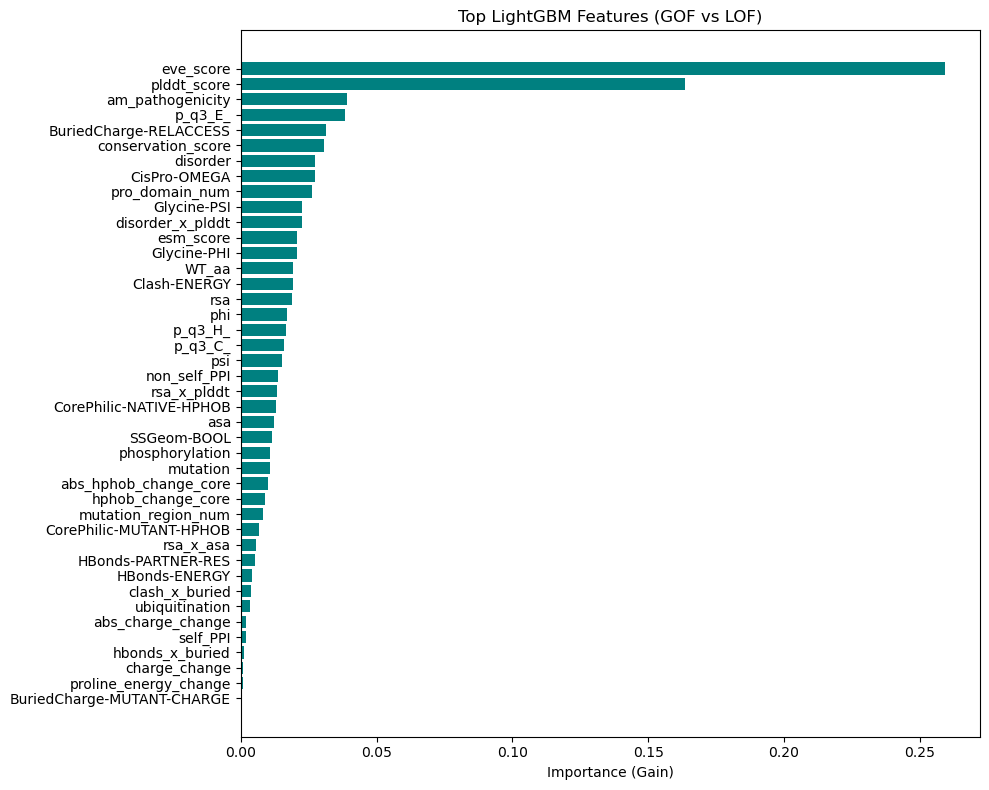


Top 10 features by Gain:
               Feature  Importance
             eve_score    0.259192
           plddt_score    0.163585
      am_pathogenicity    0.039116
               p_q3_E_    0.038491
BuriedCharge-RELACCESS    0.031573
    conservation_score    0.030490
              disorder    0.027309
          CisPro-OMEGA    0.027164
        pro_domain_num    0.026229
           Glycine-PSI    0.022408


In [16]:
# -─ 11. Feature importance (Gain) ─────────────────────────────────────────────
# CalibratedClassifierCV wraps multiple estimators (one per fold)
# We average the feature importances across all calibrated estimators

importances_list = []
for calibrated_clf in calibrated_model.calibrated_classifiers_:
    # Each calibrated_clf.estimator is the underlying LGBMClassifier
    booster = calibrated_clf.estimator.booster_
    importances_list.append(booster.feature_importance(importance_type='gain'))
    

# Average importance across all folds
importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()  # Normalize to sum to 1

feature_names = X_train_selected_lgb.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot top features (or all if less than 52)
n_top = min(52, len(feature_importance_df))

plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (Gain)')
plt.title('Top LightGBM Features (GOF vs LOF)')
plt.tight_layout()
plt.savefig("lgb_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()

# Print top 10 features
print("\nTop 10 features by Gain:")
print(feature_importance_df.head(10).to_string(index=False))

> Explaining the model using SHAP

Cracking open the LightGBM model with SHAP...


/opt/anaconda3/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


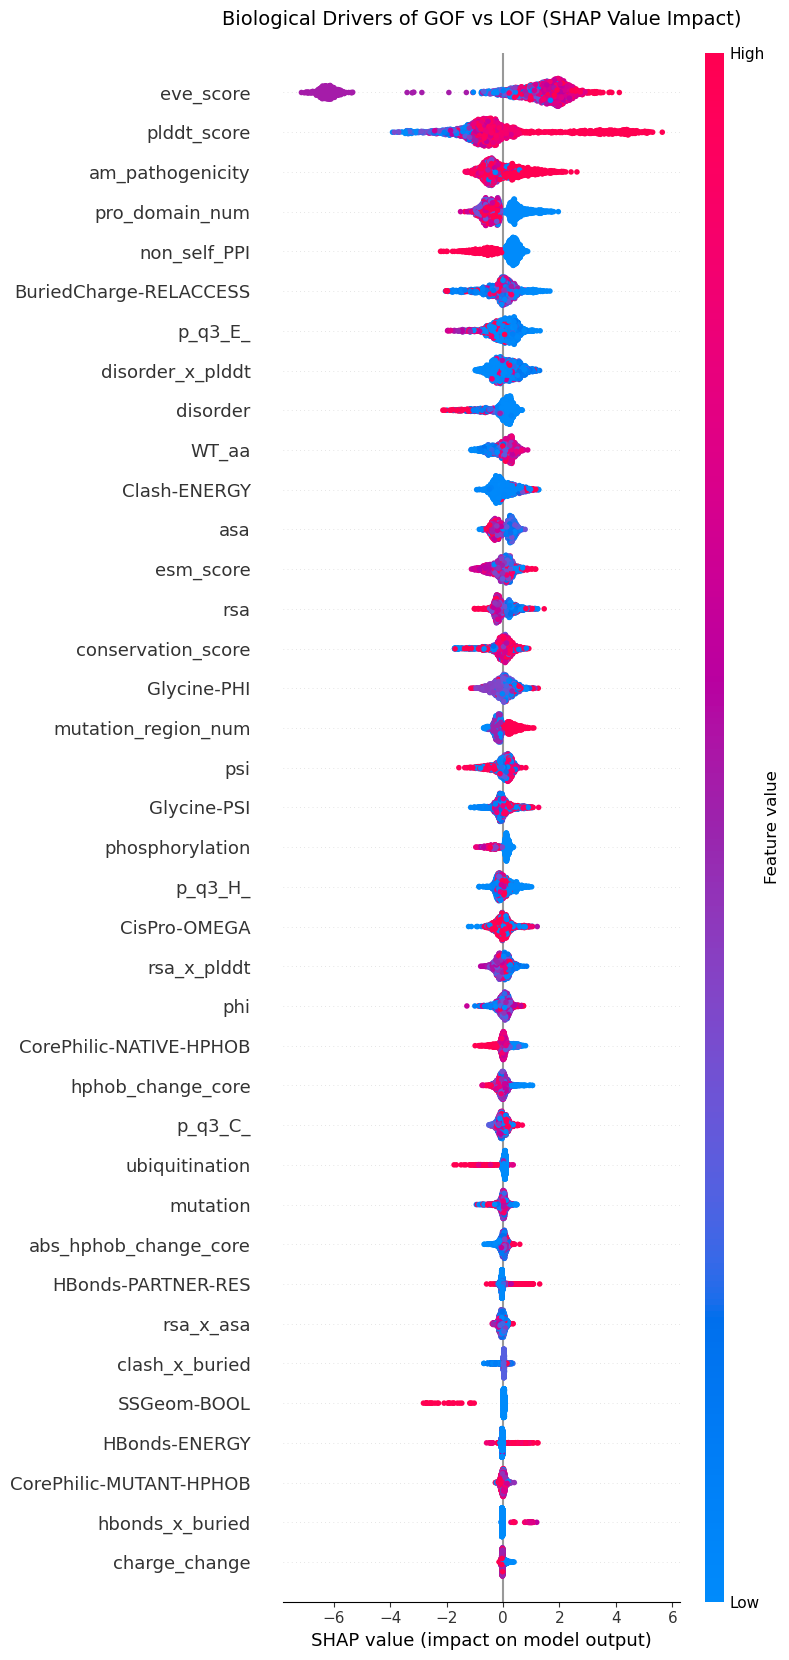

In [ ]:
import shap
import matplotlib.pyplot as plt
import lightgbm as lgb

print("Cracking open the LightGBM model with SHAP...")

# Fit a plain LightGBM model for explanation
shap_model = lgb.LGBMClassifier(
    **best_params,
    random_state=42,
    verbose=-1,
    class_weight='balanced'
)
shap_model.fit(X_train_selected_lgb, y_train_orig)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_train_selected_lgb)

# In some SHAP versions, binary classification returns a list
if isinstance(shap_values, list):
    shap_values = shap_values[1]

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train_selected_lgb, max_display=38, show=False)
plt.title("Biological Drivers of GOF vs LOF (SHAP Value Impact)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

> Check Model performance on test and External validation mutation by checking on mutations in genes that are in train and not in train data.


Confusion Matrix for Novel Test Genes:
[[291 192]
 [ 93 390]]
              precision    recall  f1-score   support

         GOF       0.76      0.60      0.67       483
         LOF       0.67      0.81      0.73       483

    accuracy                           0.70       966
   macro avg       0.71      0.70      0.70       966
weighted avg       0.71      0.70      0.70       966



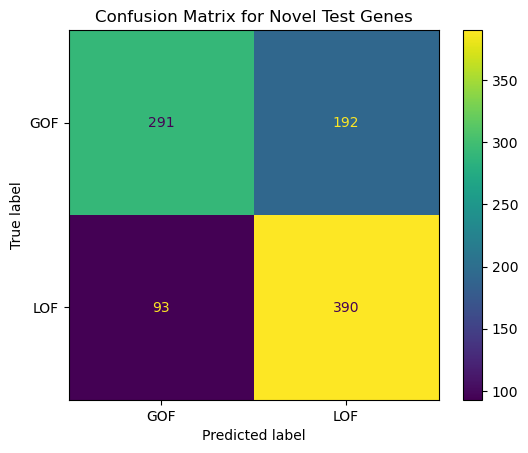

Novel Test Genes AUC: 0.763

Confusion Matrix for Novel Validation Genes:
[[ 40  33]
 [ 33 149]]
              precision    recall  f1-score   support

         GOF       0.55      0.55      0.55        73
         LOF       0.82      0.82      0.82       182

    accuracy                           0.74       255
   macro avg       0.68      0.68      0.68       255
weighted avg       0.74      0.74      0.74       255



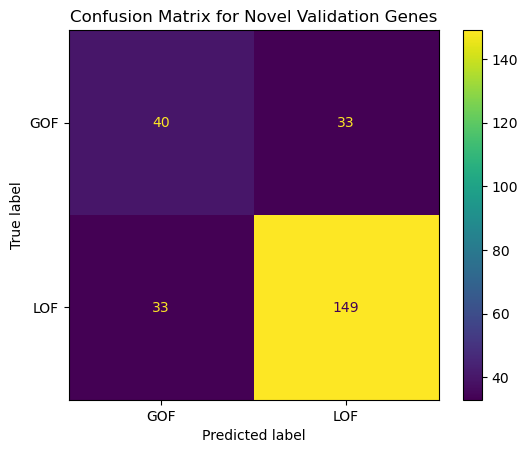

Novel Validation Genes AUC: 0.700

Confusion Matrix for Non-Novel Validation Genes:
[[186  66]
 [ 25 118]]
              precision    recall  f1-score   support

         GOF       0.88      0.74      0.80       252
         LOF       0.64      0.83      0.72       143

    accuracy                           0.77       395
   macro avg       0.76      0.78      0.76       395
weighted avg       0.79      0.77      0.77       395



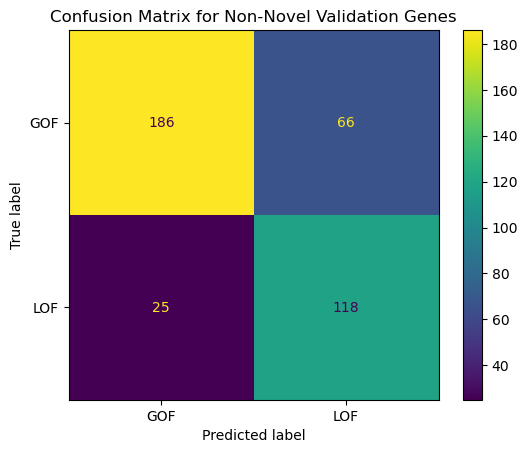

Non-Novel Validation Genes AUC: 0.840


In [12]:
# Get genes that are in training data and genes that are in test and validation data
train_genes = {idx.split('_')[0] for idx in X_train_selected_lgb.index.astype(str)}
test_genes = {idx.split('_')[0] for idx in X_test_selected_lgb.index.astype(str)}
validation_genes = {idx.split('_')[0] for idx in X_val_lgb.index.astype(str)}

# ---------------------------------------------------------
# Step 1: TEST SET
# ---------------------------------------------------------

# Merge test predictions with the original test dataframe
test_results_df = y_test_orig.to_frame(name='True_Label').copy()
test_results_df['Predicted_Label'] = y_pred_opt
test_results_df['Predicted_Prob'] = proba_test_cal
test_results_df['Gene'] = test_results_df.index.astype(str).str.split('_').str[0]

# A. Novel test genes
novel_test_genes_df = test_results_df[~test_results_df['Gene'].isin(train_genes)]  # 34

if not novel_test_genes_df.empty:
    novel_y_true = novel_test_genes_df['True_Label']
    novel_y_pred = novel_test_genes_df['Predicted_Label']
    novel_y_prob = novel_test_genes_df['Predicted_Prob']

    novel_cm = confusion_matrix(novel_y_true, novel_y_pred)
    print("\nConfusion Matrix for Novel Test Genes:")
    print(novel_cm)
    print(classification_report(novel_y_true, novel_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(novel_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Novel Test Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NovelTestGenes.png", dpi=600)
    plt.show()

    if novel_y_true.nunique() == 2:
        novel_auc = roc_auc_score(novel_y_true, novel_y_prob)
        print(f"Novel Test Genes AUC: {novel_auc:.3f}")

# B. Non-novel test genes
not_novel_test_genes_df = test_results_df[test_results_df['Gene'].isin(train_genes)]  # 526

if not not_novel_test_genes_df.empty:
    not_novel_y_true = not_novel_test_genes_df['True_Label']
    not_novel_y_pred = not_novel_test_genes_df['Predicted_Label']
    not_novel_y_prob = not_novel_test_genes_df['Predicted_Prob']

    not_novel_cm = confusion_matrix(not_novel_y_true, not_novel_y_pred)
    print("\nConfusion Matrix for Non-Novel Test Genes:")
    print(not_novel_cm)
    print(classification_report(not_novel_y_true, not_novel_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(not_novel_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Non-Novel Test Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NonNovelTestGenes.png", dpi=600)
    plt.show()

    if not_novel_y_true.nunique() == 2:
        not_novel_auc = roc_auc_score(not_novel_y_true, not_novel_y_prob)
        print(f"Non-Novel Test Genes AUC: {not_novel_auc:.3f}")

# ---------------------------------------------------------
# Step 2: VALIDATION SET
# ---------------------------------------------------------

validation_results_df = target_lgb.to_frame(name='True_Label').copy()
validation_results_df['Predicted_Label'] = y_pred_val
validation_results_df['Predicted_Prob'] = proba_val_cal
validation_results_df['Gene'] = validation_results_df.index.astype(str).str.split('_').str[0]

# A. Novel validation genes
novel_validation_genes_df = validation_results_df[~validation_results_df['Gene'].isin(train_genes)]  # 34

if not novel_validation_genes_df.empty:
    novel_val_y_true = novel_validation_genes_df['True_Label']
    novel_val_y_pred = novel_validation_genes_df['Predicted_Label']
    novel_val_y_prob = novel_validation_genes_df['Predicted_Prob']

    novel_val_cm = confusion_matrix(novel_val_y_true, novel_val_y_pred)
    print("\nConfusion Matrix for Novel Validation Genes:")
    print(novel_val_cm)
    print(classification_report(novel_val_y_true, novel_val_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(novel_val_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Novel Validation Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NovelValidationGenes.png", dpi=600)
    plt.show()

    if novel_val_y_true.nunique() == 2:
        novel_val_auc = roc_auc_score(novel_val_y_true, novel_val_y_prob)
        print(f"Novel Validation Genes AUC: {novel_val_auc:.3f}")

# B. Non-novel validation genes
not_novel_validation_genes_df = validation_results_df[validation_results_df['Gene'].isin(train_genes)]  # 526

if not not_novel_validation_genes_df.empty:
    not_novel_val_y_true = not_novel_validation_genes_df['True_Label']
    not_novel_val_y_pred = not_novel_validation_genes_df['Predicted_Label']
    not_novel_val_y_prob = not_novel_validation_genes_df['Predicted_Prob']

    not_novel_val_cm = confusion_matrix(not_novel_val_y_true, not_novel_val_y_pred)
    print("\nConfusion Matrix for Non-Novel Validation Genes:")
    print(not_novel_val_cm)
    print(classification_report(not_novel_val_y_true, not_novel_val_y_pred, target_names=['GOF', 'LOF']))

    ConfusionMatrixDisplay(not_novel_val_cm, display_labels=['GOF', 'LOF']).plot(cmap='viridis')
    plt.title("Confusion Matrix for Non-Novel Validation Genes")
    plt.savefig("lgb_bestModel_ConfusionMatrix_NonNovelValidationGenes.png", dpi=600)
    plt.show()

    if not_novel_val_y_true.nunique() == 2:
        not_novel_val_auc = roc_auc_score(not_novel_val_y_true, not_novel_val_y_prob)
        print(f"Non-Novel Validation Genes AUC: {not_novel_val_auc:.3f}")

> Prediction for benchmarking

In [ ]:
cleaned_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/MachineLearning/LoGoFunc_benchmarking/Step-1_Data extraction/cleaned_test_val_df.csv", index_col=0)  # Load the cleaned validation set
# drop any row with value == 2 in the 'goflof' column
cleaned_val2 = cleaned_val[cleaned_val['goflof'] != 2].copy()

# Step 1: predict cleaned_val2 using the calibrated LightGBM, XGB, and Random Forest models
# Random Forest predictions
cleaned_val2_rf = clean_cols(cleaned_val2.copy())
X_cleaned_val2_rf = cleaned_val2_rf[rf_features].copy()

# predict probabilities 
proba_cleaned_val2_rf = calibrated_model_rf.predict_proba(X_cleaned_val2_rf)
# predict class labels
y_pred_cleaned_val2_rf = calibrated_model_rf.predict(X_cleaned_val2_rf)
# add predicted class 
X_cleaned_val2_rf['Predicted_Label'] = y_pred_cleaned_val2_rf
# add predicted probabilities for each class
X_cleaned_val2_rf['Predicted_Prob_LOF'] = proba_cleaned_val2_rf[:, 1]  # probability of class 1 (LOF)
X_cleaned_val2_rf['Predicted_Prob_GOF'] = proba_cleaned_val2_rf[:, 0]  # probability of class 0 (GOF)
# add true labels
X_cleaned_val2_rf['True_Label'] = cleaned_val2['goflof'].values
# save the results to a CSV file
X_cleaned_val2_rf.to_csv("cleaned_val2_predictions_RF.csv", index=True)


In [18]:

# XGBoost predictions
cleaned_val2_xgb = clean_cols(cleaned_val2.copy())
X_cleaned_val2_xgb = cleaned_val2_xgb[xgb_features].copy()  

# predict probabilities
proba_cleaned_val2_xgb = calibrated_model_xgb.predict_proba(X_cleaned_val2_xgb)
# predict class labels
y_pred_cleaned_val2_xgb = calibrated_model_xgb.predict(X_cleaned_val2_xgb)
# add predicted class
X_cleaned_val2_xgb['Predicted_Label'] = y_pred_cleaned_val2_xgb
# add predicted probabilities for each class
X_cleaned_val2_xgb['Predicted_Prob_LOF'] = proba_cleaned_val2_xgb[:, 1]  # probability of class 1 (LOF) 
X_cleaned_val2_xgb['Predicted_Prob_GOF'] = proba_cleaned_val2_xgb[:, 0]  # probability of class 0 (GOF)
# add true labels
X_cleaned_val2_xgb['True_Label'] = cleaned_val2['goflof'].values
# save the results to a CSV file
X_cleaned_val2_xgb.to_csv("cleaned_val2_predictions_XGB.csv", index=True)


In [20]:

# LightGBM predictions
cleaned_val2_lgb = clean_cols(cleaned_val2.copy())
X_cleaned_val2_lgb = cleaned_val2_lgb[lgb_features].copy()  

# predict probabilities
proba_cleaned_val2_lgb = calibrated_model_lgb.predict_proba(X_cleaned_val2_lgb)
# predict class labels
y_pred_cleaned_val2_lgb = calibrated_model_lgb.predict(X_cleaned_val2_lgb)
# add predicted class
X_cleaned_val2_lgb['Predicted_Label'] = y_pred_cleaned_val2_lgb
# add predicted probabilities for each class
X_cleaned_val2_lgb['Predicted_Prob_LOF'] = proba_cleaned_val2_lgb[:, 1]  # probability of class 1 (LOF)
X_cleaned_val2_lgb['Predicted_Prob_GOF'] = proba_cleaned_val2_lgb[:, 0]  # probability of class 0 (GOF)     
# add true labels
X_cleaned_val2_lgb['True_Label'] = cleaned_val2['goflof'].values
# save the results to a CSV file
X_cleaned_val2_lgb.to_csv("cleaned_val2_predictions_LGB.csv", index=True)